# Aprendizaje Automático I

## Trabajo Práctico: Predicción de lluvia en Australia

### Facultad de Ciencias Exactas, Ingeniería y Agrimensura (FCEIA) - Universidad Nacional de Rosario (UNR)

**Integrantes:** Tomás Gimbatti y Valentino Longo 

---

### Contenidos

1. Configuración del entorno
2. Carga e inspección estructural del dataset
3. División train / test
4. Revisión inicial de datos nulos y duplicados
5. Análisis Exploratorio de Datos (EDA)
6. Imputación espacial por KNN 
7. Limpieza de datos
8. Balance de la variable objetivo
9. Codificación de variables cualitativas
10. Transformación logarítmica
11. Escalado de datos
12. Regresión logística
13. Modelo base y comparación

# 1. Configuración del entorno

In [1]:
# Importamos las librerías necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import PowerNorm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

# Semilla fija para que los resultados sean reproducibles
RANDOM_STATE = 42

# Contador para referenciar a los gráficos
N_FIG = 1

# 2. Carga e inspección estructural del dataset

**Diccionario de variables**

* **Date:** (Cualitativa) Fecha de la observación.
* **Location:** (Cualitativa) Nombre de la estación meteorológica. 
* **MinTemp:** (Continua) Temperatura mínima registrada en grados Celsius (°C) en las 24 horas previas a las 9:00 AM.
* **MaxTemp:** (Continua) Temperatura máxima registrada en grados Celsius (°C) en las 24 horas previas a las 9:00 AM.
* **Rainfall:** (Continua) Cantidad de lluvia recolectada (en milímetros) durante las 24 horas previas a las 9:00 AM.
* **Evaporation:** (Continua) Medida en milímetros (mm) acumulados en las 24 horas previas a las 9:00 AM.
* **Sunshine:** (Continua)  Número total de horas de sol brillante registradas durante todo el día.
* **WindGustDir:** (Cualitativa) Dirección de la ráfaga de viento más fuerte ocurrida en las 24 horas hasta la medianoche.
* **WindGustSpeed:** (Cualitativa) Velocidad de la ráfaga de viento más fuerte en kilómetros por hora (km/h) en las 24 horas anteriores a la medianoche.
* **WindDir9am:** (Cualitativa)  Dirección del viento registrada a las 9:00 AM.
* **WindDir3pm:** (Cualitativa)  Dirección del viento registrada a las 3:00 PM
* **WindSpeed9am:** (Cualitativa) Velocidad del viento en km/h medida como el promedio de los 10 minutos anteriores a las 9:00 AM.
* **WindSpeed3pm:** (Cualitativa) Velocidad del viento en km/h medida como el promedio de los 10 minutos anteriores a las 3:00 PM.
* **Humidity9am:** (Continua) Porcentaje de humedad relativa registrado a las 9:00 AM.
* **Humidity3pm:** (Continua) Porcentaje de humedad relativa registrado a las 3:00 PM.
* **Pressure9am:** (Continua) Presión atmosférica reducida al nivel del mar medida en hectopascales (hPa) a las 9:00 AM.
* **Pressure3pm:** (Continua) Presión atmosférica reducida al nivel del mar medida en hectopascales (hPa) a las 3:00 PM.
* **Cloud9am:** (Discreta) Fracción de cielo cubierta por nubes a las 9:00 AM medido en octas (octavos de cielo cubierto).
* **Cloud3pm:** (Discreta) Fracción de cielo cubierta por nubes a las 3:00 PM medido en octas (octavos de cielo cubierto).
* **Temp9am:** (Continua) Temperatura en grados Celsius (°C) medida a las 9:00 AM.
* **Temp3pm:** (Continua) Temperatura en grados Celsius (°C) medida a las 3:00 PM.
* **RainToday:** (Cualitativa Dicotómica) Toma el valor "Yes" si la precipitación (Rainfall) en las 24 horas previas a las 9:00 AM supera 1 mm, y "No" en caso contrario.
* **RainTomorrow:** (Cualitativa Dicotómica) Se calcula directamente a partir de la variable (RainfallTomorrow), si la lluvia del día de mañana supera 1.0 mm, toma el valor de "Yes" y "No" en caso contrario.
* **RainfallTomorrow:** (Cuantitativa) Cantidad de lluvia registrada al día siguiente en milímetros (mm).

In [2]:
# Lectura del archivo .csv
df = pd.read_csv("weatherAUS_2026C2.csv")

In [3]:
# Mostramos información del dataset sobre todas las columnas
print(f'Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas\n')
resumen = pd.DataFrame({
    "Cantidad de no nulos": df.notna().sum(),
    "Tipo de dato": df.dtypes
})

resumen.index.name = "Columna"
display(resumen)

Dimensiones del dataset: 145412 filas x 25 columnas



,Cantidad de no nulos,Tipo de dato
Columna,,
Unnamed: 0,145412,int64
Date,145412,str
Location,145412,str
MinTemp,143928,float64
MaxTemp,144159,float64
Rainfall,142152,float64
Evaporation,82658,float64
Sunshine,75616,float64
WindGustDir,135096,str


In [4]:
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


In [5]:
df.tail()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
145407,145454,2017-06-20,Uluru,2.6,22.0,0.0,NaN,NaN,E,29.0,...,26.5,1024.8,1021.2,NaN,NaN,10.1,21.6,No,No,0.0
145408,145455,2017-06-21,Uluru,3.1,23.2,0.0,NaN,NaN,E,31.0,...,24.7,1024.3,1020.5,NaN,NaN,11.1,21.5,No,No,0.0
145409,145456,2017-06-22,Uluru,3.6,26.0,0.0,NaN,NaN,NNW,21.0,...,21.4,1023.3,1018.4,NaN,NaN,11.8,24.5,No,No,0.0
145410,145457,2017-06-23,Uluru,4.8,27.4,0.0,NaN,NaN,N,39.0,...,23.7,1021.0,1016.0,NaN,NaN,12.0,26.9,No,No,0.0
145411,145458,2017-06-24,Uluru,7.5,26.5,0.0,NaN,NaN,SE,28.0,...,27.1,1019.8,1016.2,3.0,2.0,14.7,26.8,No,No,0.0


In [6]:
# Eliminamos la primera columna y la de RainFallTomorrow
df_limpio = df.drop(columns=["Unnamed: 0", "RainfallTomorrow"], errors="ignore").copy()


Decidimos eliminar "Unnamed: 0" ya que era una variable que no nos aportaba nada al actuar como índice. También eliminamos "RainfallTomorrow" porque generaría una fuga de datos al contener información sobre la precipitación del día de mañana que con datos nuevos esa variable no se conoce ya que no se puede medir la precipitación de un día que todavía no sucedió. 

In [7]:
# Mostramos 5 registros aleatorios con la columna eliminada
df_limpio.sample(5, random_state=RANDOM_STATE)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
36428,2017-03-27,SydneyAirport,20.7,28.9,0.0,5.8,11.0,NE,52.0,NNW,...,73.9,67.2,1016.8,1011.9,1.0,1.0,23.8,27.2,No,No
131530,2013-06-28,Hobart,5.2,13.6,0.0,1.0,5.0,NW,30.0,NNW,...,75.0,59.8,1021.2,1021.9,NaN,NaN,7.4,12.1,No,No
30576,2009-03-16,Sydney,16.5,27.0,0.4,6.8,10.8,NaN,NaN,W,...,40.6,29.5,1011.1,1008.1,1.0,0.0,19.0,26.4,No,No
23078,2014-08-17,NorfolkIsland,10.1,17.7,0.6,3.0,6.1,E,36.0,E,...,59.4,57.2,1023.5,1020.5,7.0,7.0,14.6,15.8,No,No
123321,2016-03-12,Perth,18.4,33.2,0.0,8.4,11.2,SSW,40.0,ESE,...,56.0,47.6,1015.9,1012.2,0.0,0.0,25.4,28.7,No,No


In [8]:
# Separamos las variables por tipo
cols_numericas = df_limpio.select_dtypes(include=[np.number]).columns.tolist()
cols_discretas = ['Cloud3pm', 'Cloud9am']
cols_continuas = [col for col in cols_numericas if col not in cols_discretas]
cols_categoricas = df_limpio.select_dtypes(include=['str']).columns.tolist()

print(f'Variables numéricas ({len(cols_numericas)}): {cols_numericas}')
print(f'Variables categóricas ({len(cols_categoricas)}): {cols_categoricas}')

Variables numéricas (16): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Variables categóricas (7): ['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']


# 3. División train / test

Dividimos el dataset en entrenamiento (80%) y prueba (20%) antes de imputar y antes de seguir con el análisis. Todos los procedimientos que aprenden algo de los datos (la imputación, el escalado, los modelos) se ajustan únicamente con el conjunto de entrenamiento. Si el imputador se ajustara con todos los datos, la información del test se filtraría al modelo (data leakage) y la evaluación final dejaría de ser una medición honesta sobre datos nunca vistos.

Los registros con valores faltantes se reparten entre los dos conjuntos como cualquier otro registro, y se imputan después de la división. 

No divimos en train y test de manera aleatoria, ya que en ese caso podríamos predecir si el lunes llovío con la información entrenada del martes siguiente, generando fuga de datos. Lo que hicimos fue ordenar los datos por fecha y obtuvimos una fecha de corte para dividir al conjunto de datos en aproximadamente 80/20.

In [9]:
# Realizamos la división train-test buscando la fecha cuyo corte deja la proporción de filas más cercana a 80/20.
df_limpio["Date"] = pd.to_datetime(df_limpio["Date"], errors="raise")

filas_por_fecha = df_limpio.groupby("Date", sort=True).size()
filas_objetivo_train = 0.80 * len(df_limpio)
fecha_corte = (filas_por_fecha.cumsum() - filas_objetivo_train).abs().idxmin()

train = df_limpio.loc[df_limpio["Date"] <= fecha_corte].copy()
test = df_limpio.loc[df_limpio["Date"] > fecha_corte].copy()

print(f"Fecha de corte: {fecha_corte.date()}")
print(f"Train: {len(train):,} filas ({len(train) / len(df_limpio):.2%})")
print(f"Test:  {len(test):,} filas ({len(test) / len(df_limpio):.2%})")

Fecha de corte: 2015-11-08
Train: 116,306 filas (79.98%)
Test:  29,106 filas (20.02%)


In [10]:
X_train = train.drop(columns=["RainTomorrow"])
y_train = train["RainTomorrow"]

X_test = test.drop(columns=["RainTomorrow"])
y_test = test["RainTomorrow"]

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

X_train: (116306, 22) | y_train: (116306,)
X_test:  (29106, 22) | y_test:  (29106,)


# 4. Revisión inicial de datos nulos y duplicados

In [11]:
# Reporte de valores nulos por columna
nulos = X_train.isnull().sum()
pct_nulos = (nulos / len(X_train)) * 100

reporte_nulos = pd.DataFrame({
    'Nulos': nulos,
    'Porcentaje (%)': pct_nulos.round(2),
    'Tipo': X_train.dtypes
})

print('Reporte de Valores Nulos:')
print('=' * 50)
print(reporte_nulos)
print(f'\nTotal de celdas con nulos: {nulos.sum()} ({nulos.sum() / X_train.size * 100:.2f}% del dataset)')

Reporte de Valores Nulos:
               Nulos  Porcentaje (%)            Tipo
Date               0            0.00  datetime64[us]
Location           0            0.00             str
MinTemp         1085            0.93         float64
MaxTemp          881            0.76         float64
Rainfall        2606            2.24         float64
Evaporation    45916           39.48         float64
Sunshine       50076           43.06         float64
WindGustDir     8545            7.35             str
WindGustSpeed   8482            7.29         float64
WindDir9am      8871            7.63             str
WindDir3pm      2815            2.42             str
WindSpeed9am    1568            1.35         float64
WindSpeed3pm    1761            1.51         float64
Humidity9am     2115            1.82         float64
Humidity3pm     2328            2.00         float64
Pressure9am    11866           10.20         float64
Pressure3pm    11832           10.17         float64
Cloud9am       43110

In [12]:
# Observamos la cantidad de valores nulos por registro
nulos_por_registro = X_train.isna().sum(axis=1).value_counts().sort_index()

resumen_nulos = nulos_por_registro.rename_axis(
    "Cantidad de valores nulos"
).reset_index(name="Cantidad de registros")

display(resumen_nulos)

,Cantidad de valores nulos,Cantidad de registros
0,0,49344
1,1,8823
2,2,14112
3,3,6784
4,4,21288
5,5,2904
6,6,8335
7,7,1617
8,8,781
9,9,168


In [13]:
# Porcentaje de registros que presentan algún valor nulo
nulos = resumen_nulos[resumen_nulos["Cantidad de valores nulos"] >= 1]["Cantidad de registros"].sum()
porcentaje_nulos = (nulos / len(X_train)) * 100
print(f"Porcentaje de registros que presentan algún valor nulo: {porcentaje_nulos.round(2)}%")

Porcentaje de registros que presentan algún valor nulo: 57.57%


In [14]:
# Analizamos porcentaje de datos duplicados
n_duplicados = X_train.duplicated().sum()
print(f'Registros duplicados: {n_duplicados} ({(n_duplicados / len(X_train) * 100).round(2)}%)')

Registros duplicados: 0 (0.0%)


In [15]:
# Eliminamos los registros con target nulo (en X_train e y_train a la vez)

registros_antes = len(X_train)
mascara_target = y_train.notna()          # True donde el target está presente

X_train = X_train.loc[mascara_target].copy()
y_train = y_train.loc[mascara_target].copy()

eliminados = registros_antes - len(y_train)

valores_a_imputar = X_train.isna().sum().sum()
registros_con_faltantes = X_train.isna().any(axis=1).sum()

print(f"Registros eliminados por target nulo: {eliminados:,}")
print(f"Registros restantes: {len(y_train):,} de {registros_antes:,}")
print(f"Valores faltantes en variables predictoras por imputar: {valores_a_imputar:,}")
print(f"Registros restantes con al menos un faltante: {registros_con_faltantes:,}")

Registros eliminados por target nulo: 2,605
Registros restantes: 113,701 de 116,306
Valores faltantes en variables predictoras por imputar: 235,603
Registros restantes con al menos un faltante: 64,491


Elegimos eliminar los registros con valores nulso en el target porque sin variable objetivo, un registro no sirve para entrenar (no hay error que calcular) ni para evaluar (no hay valor real contra el cual comparar la predicción). Tampoco corresponde imputar el target: sería inventar la respuesta que el modelo debe aprender.

# 5. Análisis Exploratorio de Datos (EDA)

## 5.1. Métricas de variables cuantitativas

In [16]:
X_train.describe()

,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,113701,113233.000000,113478.000000,112574.000000,69366.000000,65188.000000,106029.000000,112498.000000,112303.000000,112226.000000,112009.000000,102639.000000,102674.000000,72377.000000,71086.000000,112895.000000,112718.000000
mean,2012-05-22 21:34:18.251026,11.949036,22.957778,2.345968,5.300033,7.587811,40.063662,14.055797,18.685253,68.810848,51.530810,1017.799328,1015.410490,4.330436,4.430000,16.760314,21.474769
min,2007-11-01 00:00:00,-9.700000,-3.900000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.300000,980.000000,0.000000,0.000000,-6.500000,-4.800000
25%,2010-08-01 00:00:00,7.400000,17.800000,0.000000,2.600000,4.800000,31.000000,7.000000,12.000000,56.900000,36.700000,1013.000000,1010.600000,1.000000,2.000000,12.100000,16.500000
50%,2012-05-22 00:00:00,11.800000,22.300000,0.000000,4.600000,8.400000,38.000000,13.000000,18.000000,69.800000,51.900000,1017.800000,1015.400000,5.000000,5.000000,16.500000,20.900000
75%,2014-03-18 00:00:00,16.600000,27.900000,0.800000,7.200000,10.600000,48.000000,19.000000,24.000000,83.100000,65.600000,1022.600000,1020.200000,7.000000,7.000000,21.300000,26.200000
max,2015-11-08 00:00:00,34.100000,49.100000,371.000000,82.400000,14.300000,135.000000,88.000000,86.000000,100.000000,100.000000,1041.200000,1039.800000,9.000000,9.000000,39.800000,46.900000
std,NaN,6.393345,7.051411,8.493096,3.988394,3.772337,13.666441,8.977627,8.911121,19.074452,20.775919,7.141179,7.068966,2.877412,2.704247,6.463057,6.889246


Observamos que en Rainfall, la mediana es 0 mm, la media es 2,35 mm y el máximo alcanza 371 mm, esto permite plantear la hipótesis de una distribución concentrada en valores bajos, con asimetría hacia la derecha y una cola que indica días con una lluvia intensa. Evaporation también tiene un máximo de 82,4 mm muy por encima de su tercer cuartil 7,2 mm, por lo que podría presentar una cola derecha y observaciones extremas. En cambio, las temperaturas y las presiones tienen medias y medianas relativamente cercanas, aunque sus mínimos y máximos amplios podrían incluir valores alejados del centro. En las velocidades del viento la media supera algo a la mediana, otra posible señal de asimetría positiva.

En la siguiente comprobación se revisa aparte que Cloud9am y Cloud3pm respeten su dominio válido de 0 a 8, ya que el describe() nos indicó un valor máximo de 9, por fuera de su rango de valores válidos. Por las demás variables, sus valores se encuentran en valores que podrían ser reales y que son válidos en su dominio.

In [17]:
# Cloud9am y Cloud3pm representan octas de nubosidad, por lo que su dominio válido es 0-8.
cols_cloud = ["Cloud9am", "Cloud3pm"]
valores_invalidos_train = (train[cols_cloud].lt(0) | train[cols_cloud].gt(8)) & train[cols_cloud].notna()
valores_invalidos_test = (test[cols_cloud].lt(0) | test[cols_cloud].gt(8)) & test[cols_cloud].notna()
filas_invalidas_train = valores_invalidos_train.any(axis=1)
filas_invalidas_test = valores_invalidos_test.any(axis=1)

print("Valores fuera del dominio válido [0, 8] por variable:")
display(pd.DataFrame({"Train": valores_invalidos_train.sum(), "Test": valores_invalidos_test.sum()}))
print(f"Filas eliminadas: {filas_invalidas_train.sum():,} en train y {filas_invalidas_test.sum():,} en test.")

# Aplicamos la misma limpieza a train/test y mantenemos X e y alineados.
indices_invalidos_train = train.index[filas_invalidas_train]
indices_invalidos_test = test.index[filas_invalidas_test]
train = train.drop(index=indices_invalidos_train).copy()
test = test.drop(index=indices_invalidos_test).copy()
X_train = X_train.drop(index=indices_invalidos_train, errors="ignore").copy()
y_train = y_train.drop(index=indices_invalidos_train, errors="ignore").copy()
X_test = X_test.drop(index=indices_invalidos_test, errors="ignore").copy()
y_test = y_test.drop(index=indices_invalidos_test, errors="ignore").copy()

print(f"Filas restantes: train={len(X_train):,}, test={len(X_test):,}.")

Valores fuera del dominio válido [0, 8] por variable:


,Train,Test
Cloud9am,2,0
Cloud3pm,1,0


Filas eliminadas: 3 en train y 0 en test.
Filas restantes: train=113,698, test=29,106.


La comprobación del dominio confirma tres observaciones inválidas en train: dos en Cloud9am y una en Cloud3pm; en test no aparecen valores fuera del rango. Como estas variables representan octas de nubosidad y su dominio permitido es de 0 a 8, se eliminan las tres filas afectadas de train antes de continuar el EDA y el modelado.

## 5.2. Distribución de las variables cuantitativas continuas

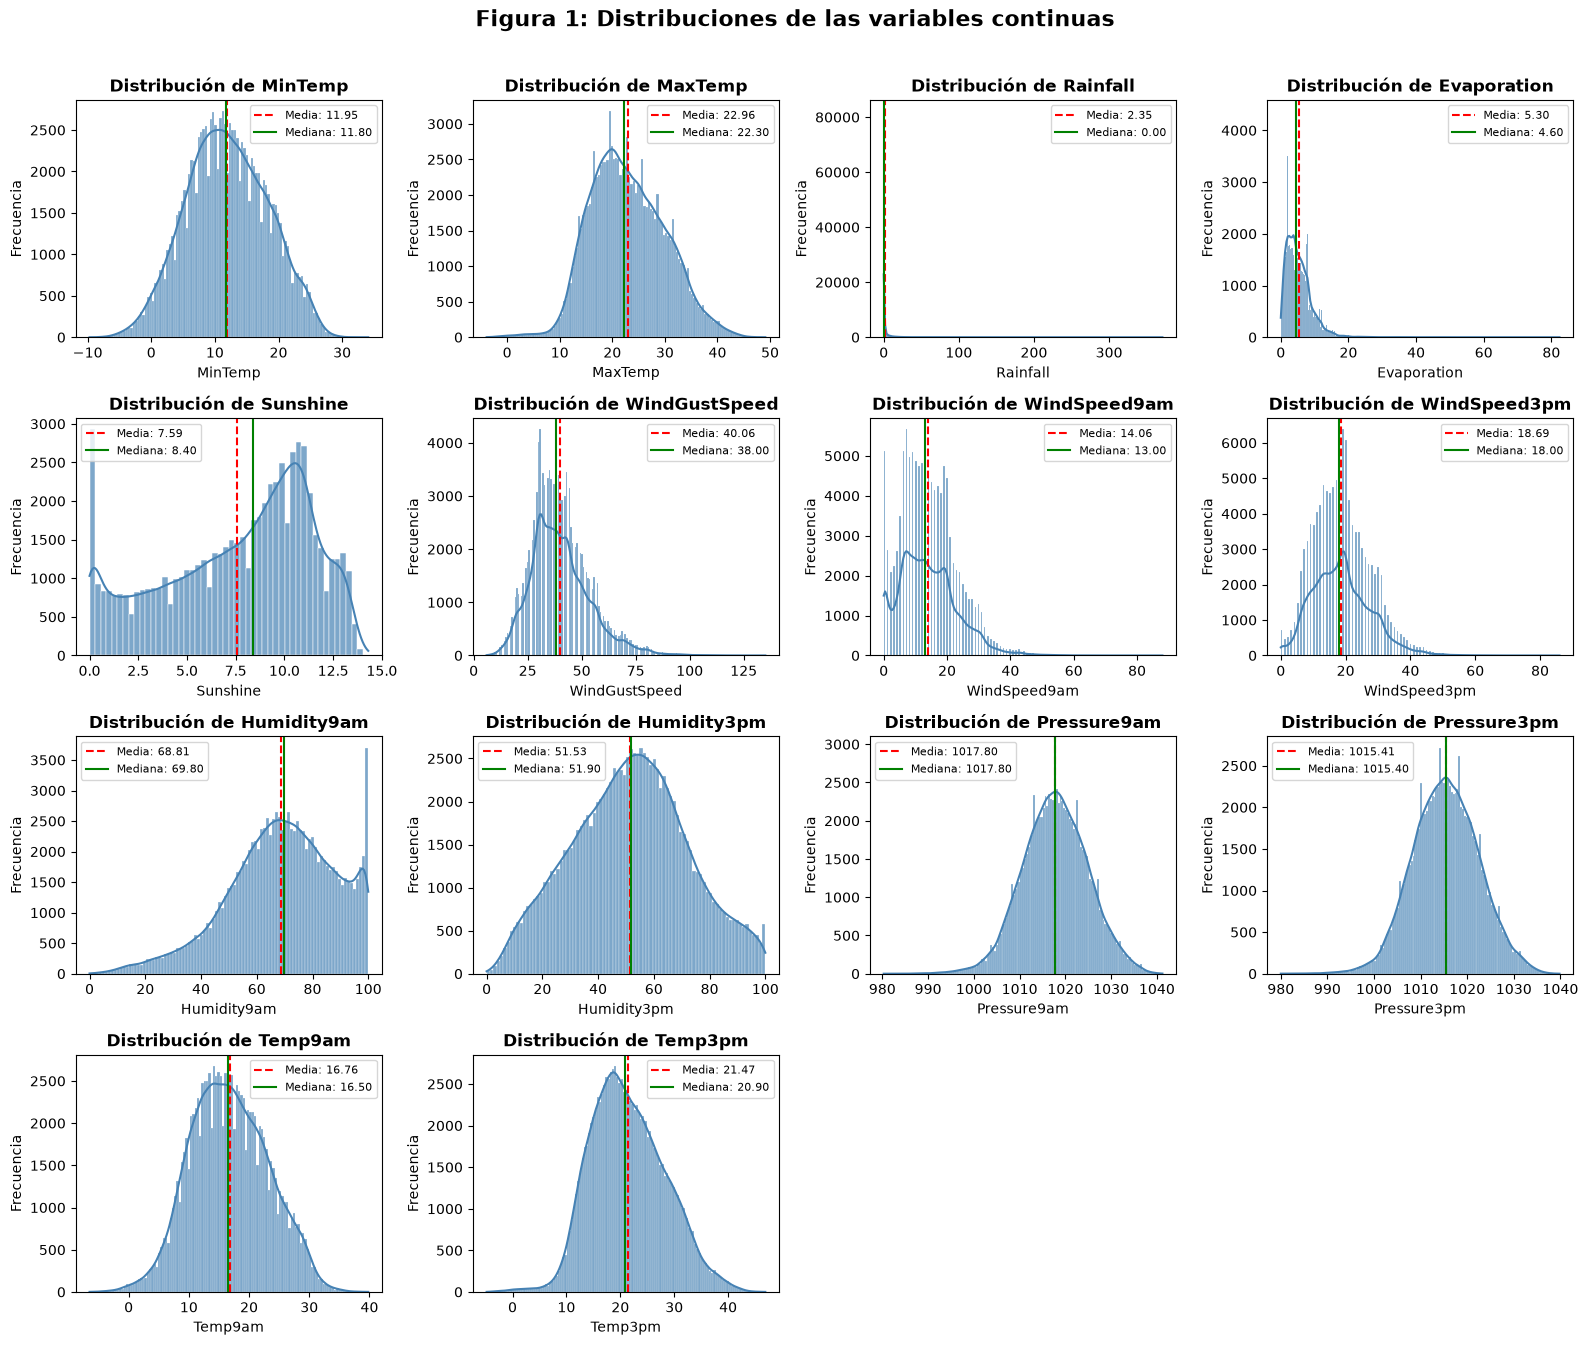

In [18]:
## Histogramas y estimación de densidad (KDE) de las variables continuas, con media y mediana

fig, axes = plt.subplots(5, 4, figsize=(16, 16))
axes = axes.flatten()

for i, col in enumerate(cols_continuas):
    ax = axes[i]
    sns.histplot(X_train[col], kde=True, ax=ax, color='steelblue', edgecolor='white', alpha=0.7)

    media = X_train[col].mean()
    mediana = X_train[col].median()
    ax.axvline(media, color='red', linestyle='--', linewidth=1.5, label=f'Media: {media:.2f}')
    ax.axvline(mediana, color='green', linestyle='-', linewidth=1.5, label=f'Mediana: {mediana:.2f}')

    ax.set_title(f'Distribución de {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=8)

for j in range(len(cols_continuas), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'Figura {N_FIG}: Distribuciones de las variables continuas',
              fontsize=16, fontweight='bold', y=1.01)
N_FIG += 1
plt.tight_layout()
plt.show()

la figura 1 permite apreciar que las variables MinTemp, Pressure9am y Pressure3pm presentan perfiles aproximadamente unimodales y cercanos a una forma acampanada; las temperaturas muestran cierta asimetría hacia valores altos. En Rainfall se distingue claramente, ya que la mayor parte de las observaciones se concentra cerca de cero y aparece una cola muy larga hacia la derecha como se había teorizado cuando calculamos sus métricas. Además, Evaporation y las velocidades del viento también muestran colas hacia valores altos, mientras que las humedades tienen perfiles distintos entre la mañana y la tarde; en Humidity9am se observa acumulación en el extremo de 100, lo que indica que hubo una gran cantidad de mañanas húmedas. Sunshine presenta una frecuencia visible en cero y mayor concentración en valores altos, por lo que podría combinar observaciones sin horas de sol con días soleados.

## 5.3. Boxplots para variables cuantitativas continuas 

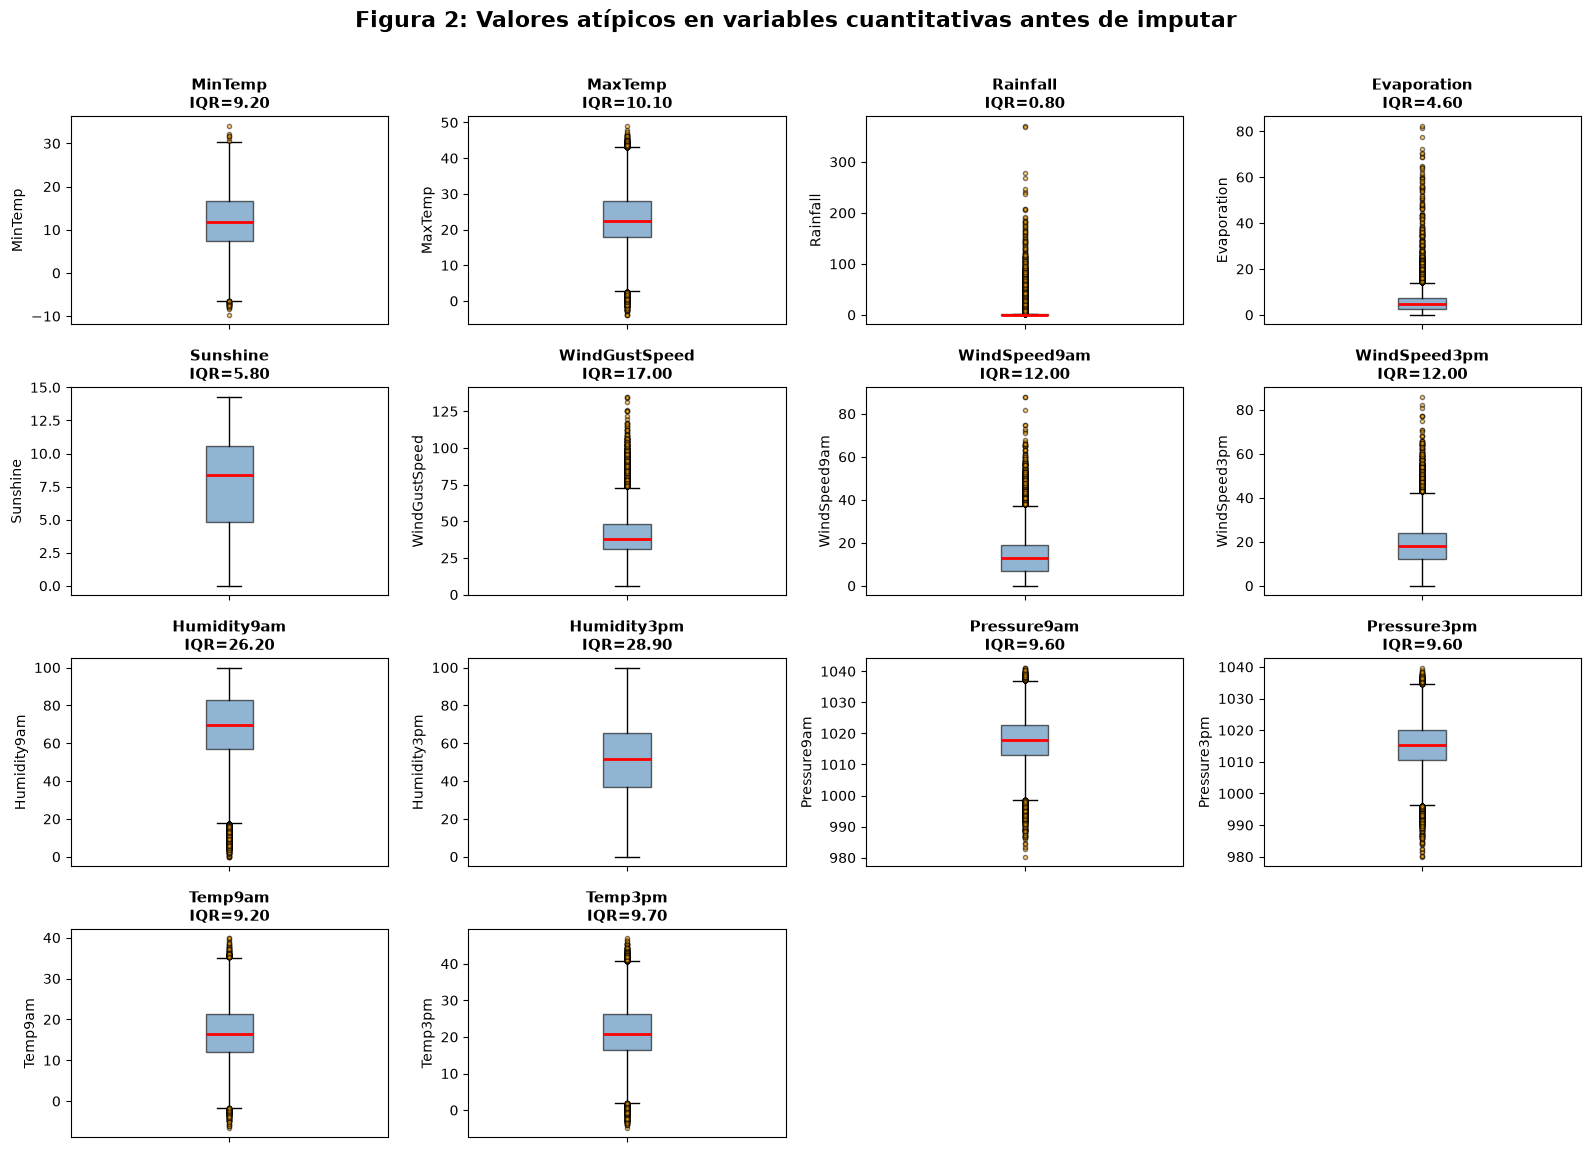

In [19]:
fig, axes = plt.subplots(5, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(cols_continuas):
    datos = X_train[col].dropna()  
    axes[i].boxplot(datos, orientation="vertical", patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.6),
                    medianprops=dict(color='red', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='orange', markersize=3, alpha=0.5))
    q1, q3 = datos.quantile(0.25), datos.quantile(0.75)
    axes[i].set_title(f'{col}\nIQR={q3 - q1:.2f}', fontweight='bold', fontsize=11)
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis='x', labelbottom=False)

for j in range(len(cols_continuas), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'Figura {N_FIG}: Valores atípicos en variables cuantitativas antes de imputar',
            fontsize=16, fontweight='bold', y=1.01)
N_FIG += 1
plt.tight_layout()
plt.show()

La figura 2 confirma que hay observaciones fuera de los bigotes en varias variables continuas. Rainfall tiene una gran cantidad de puntos por encima del bigote superior, coherente con la cola larga observada en su histograma; Evaporation y las velocidades del viento también muestran numerosos puntos altos. En MinTemp, MaxTemp, Temp9am y Temp3pm aparecen puntos en ambos extremos, y en Pressure9am y Pressure3pm hay valores alejados tanto por debajo como por encima del rango central. En cambio, Sunshine y Humidity3pm no muestran puntos fuera de los bigotes en esta representacion.

Los puntos se consideran atípicos según la regla gráfica habitual de 1,5 veces el rango intercuartílico; eso no demuestra que sean errores. La decisión de eliminarlos o no se va a tratar en la sección de limpieza de datos. La presencia de muchos valores alejados del centro justifica evaluar un escalado robusto, que reduce la influencia del rango central y de valores extremos sobre la escala, pero no elimina ni recorta los outliers.

## 5.4. Distribución de las variables cuantitativas discretas

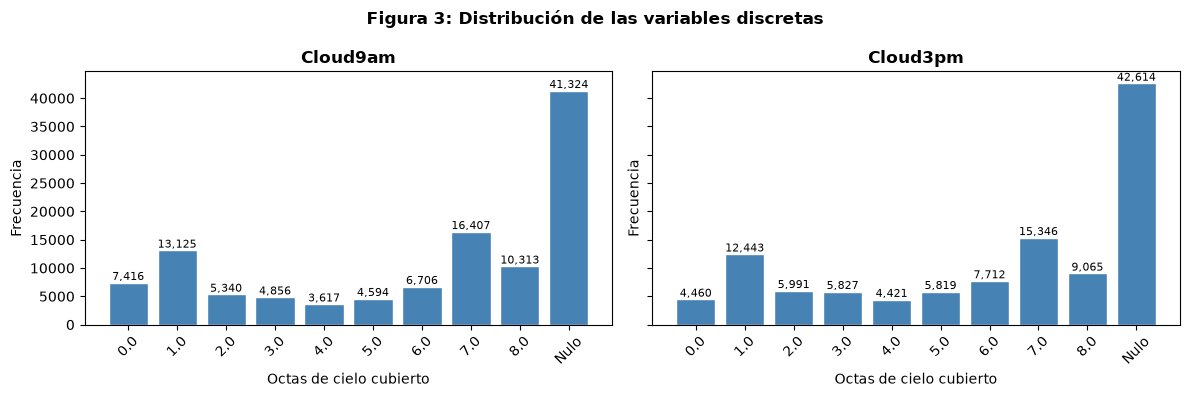

In [20]:
# Distribución de las variables discretas 
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, columna in zip(axes, ["Cloud9am", "Cloud3pm"]):
    conteos = X_train[columna].value_counts(dropna=False).sort_index(na_position="last")
    etiquetas = ["Nulo" if pd.isna(valor) else str(valor) for valor in conteos.index]
    ax.bar(etiquetas, conteos.values, color="steelblue", edgecolor="white")
    ax.set_title(columna, fontweight="bold")
    ax.set_xlabel("Octas de cielo cubierto")
    ax.set_ylabel("Frecuencia")
    ax.tick_params(axis="x", rotation=45)
    for posicion, frecuencia in enumerate(conteos.values):
        ax.text(posicion, frecuencia, f"{frecuencia:,}", ha="center", va="bottom", fontsize=8)

fig.suptitle(f"Figura {N_FIG}: Distribución de las variables discretas", fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

En la figura 3 vemos que Cloud9am y Cloud3pm son variables discretas con frecuencias repartidas entre octas y una proporción elevada de faltantes: 36,34 % y 37,48 %, respectivamente. En ambas, el valor más frecuente es 7. 

## 5.5. Distribución de las variables cualitativas

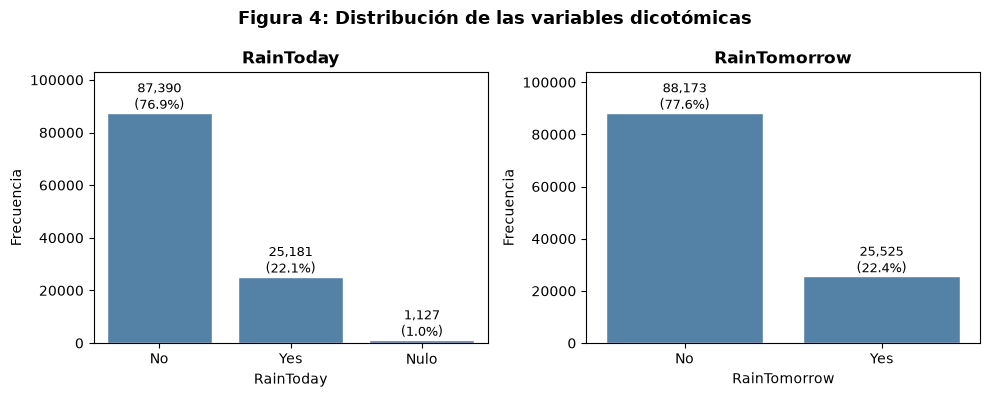

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (nombre, serie) in zip(axes, [("RainToday", X_train["RainToday"]),
                                      ("RainTomorrow", y_train)]):
    conteo = serie.value_counts(dropna=False)
    conteo.index = conteo.index.fillna("Nulo")
    sns.barplot(x=conteo.index, y=conteo.values, ax=ax, color="steelblue", edgecolor="white")
    for i, v in enumerate(conteo.values):
        ax.text(i, v, f"{v:,}\n({v / conteo.sum():.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(nombre, fontweight="bold")
    ax.set_ylabel("Frecuencia")
    ax.set_ylim(0, conteo.max() * 1.18)

plt.suptitle(f"Figura {N_FIG}: Distribución de las variables dicotómicas",
             fontsize=13, fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

Analizando la figura 4 obsevamos que En RainToday, 76,9 % de los registros son No, 22,1 % Yes y 1,0 % no tiene dato. En RainTomorrow, 77,6 % son No y 22,4 % Yes; como es la variable objetivo, esto muestra un desbalance moderado (aproximadamente 3,5 días sin lluvia por cada día lluvioso). Por eso, un clasificador que siempre predijera No ya alcanzaría cerca de 77,6 % de accuracy en este train, aunque no detectaría ningún día lluvioso. Al evaluar la regresión logística habrá que mirar también recall, precision, F1 u otras métricas y la matriz de confusión. La distribución de RainToday describe el predictor, pero por sí sola no muestra cómo se relaciona con RainTomorrow, eso se analiza en la Figura 7.

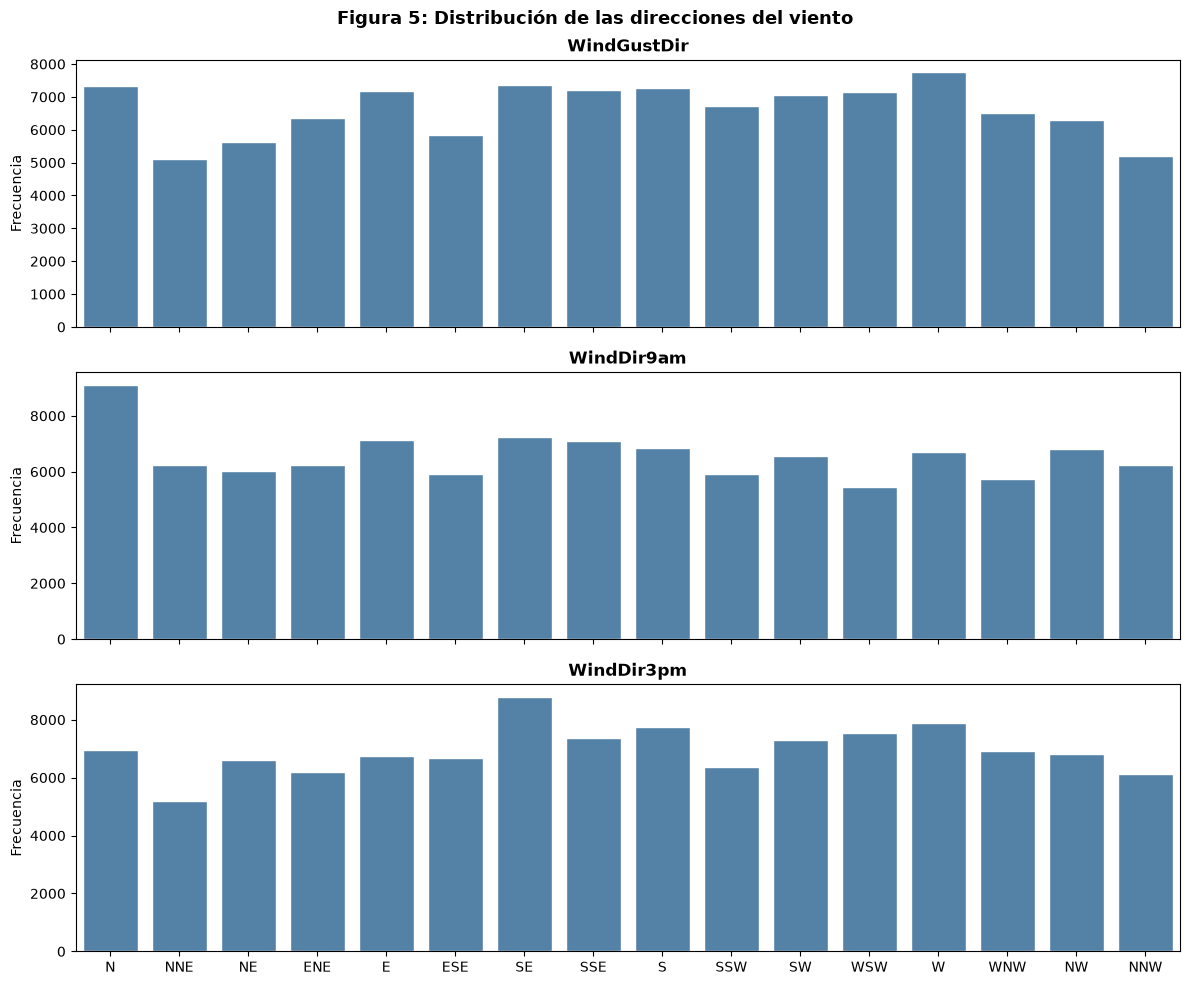

In [22]:
orden_viento = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
                "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
cols_viento = ["WindGustDir", "WindDir9am", "WindDir3pm"]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, cols_viento):
    sns.countplot(x=X_train[col], order=orden_viento, ax=ax, color="steelblue", edgecolor="white")
    pct_nulos = X_train[col].isna().mean() * 100
    ax.set_title(f"{col}", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Frecuencia")

plt.suptitle(f"Figura {N_FIG}: Distribución de las direcciones del viento",
             fontsize=13, fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

Análisis de la Figura 5: Las barras muestran cuántas observaciones hay para cada una de las 16 direcciones. Entre los valores observados, las frecuencias están distribuidas entre varias direcciones: no hay una única categoría que concentre la mayoría de los registros. 

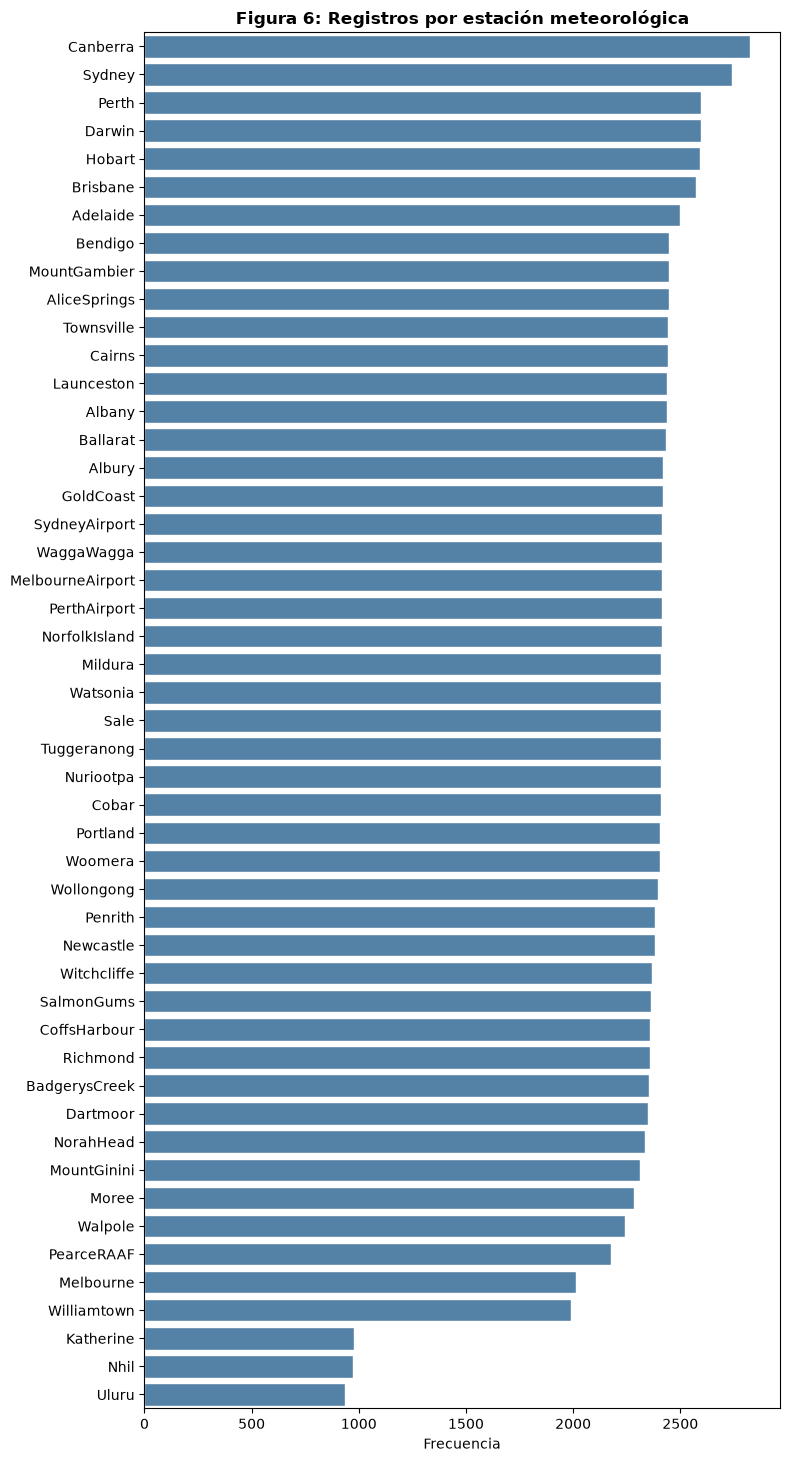

In [23]:
conteo_loc = X_train["Location"].value_counts()

fig, ax = plt.subplots(figsize=(8, 0.28 * len(conteo_loc) + 1))
sns.barplot(x=conteo_loc.values, y=conteo_loc.index, ax=ax, color="steelblue", edgecolor="white")
ax.set_title(f"Figura {N_FIG}: Registros por estación meteorológica", fontweight="bold")
ax.set_xlabel("Frecuencia")
ax.set_ylabel("")
N_FIG += 1
plt.tight_layout()
plt.show()

En la figura 6 se observa la cantidad de observaciones por cada una estaciones meteorológicas. Se observa que Canberra y Sydney tienen más registros, superando los 2500, mientras que Katherine, Nhil y Uluru tienen menos ay que no llegan a los 1000. El gráfico describe la cobertura del dataset por localidad; no indica qué ciudad es más lluviosa, porque muestra conteos y no proporciones de RainTomorrow.

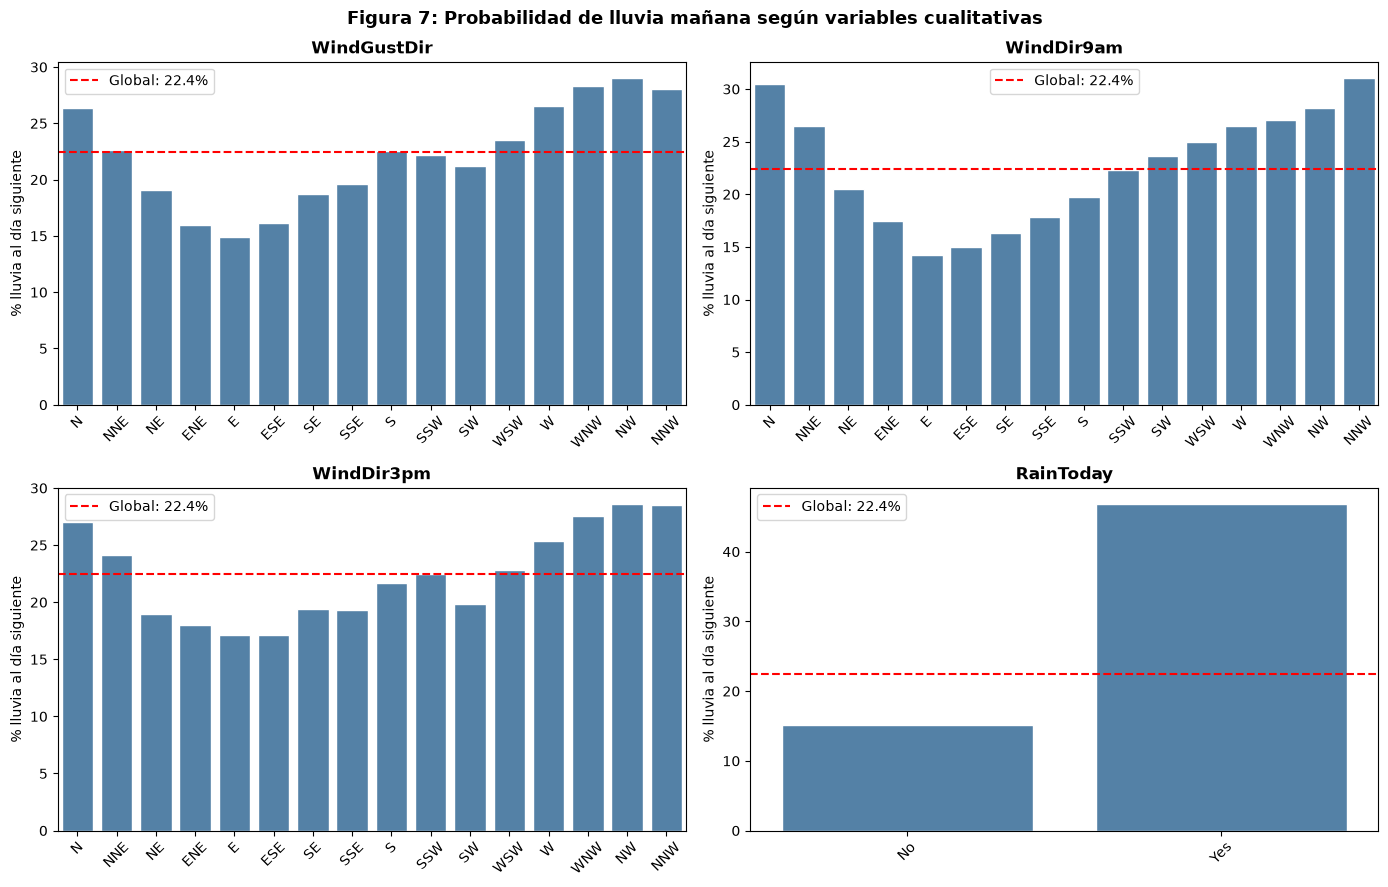

In [24]:
tasa_global = (y_train == "Yes").mean()
y_bin = (y_train == "Yes").astype(int)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, col in zip(axes, ["WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]):
    tasa = y_bin.groupby(X_train[col]).mean() * 100
    if col != "RainToday":
        tasa = tasa.reindex(orden_viento)
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax, color="steelblue", edgecolor="white")
    ax.axhline(tasa_global * 100, color="red", linestyle="--", label=f"Global: {tasa_global:.1%}")
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("% lluvia al día siguiente")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.suptitle(f"Figura {N_FIG}: Probabilidad de lluvia mañana según variables cualitativas",
             fontsize=13, fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

Análisis de la Figura 7: La línea roja representa la proporción global de RainTomorrow = Yes en train (22,4 %). En RainToday, la tasa de lluvia al día siguiente es aproximadamente 46,9 % cuando hoy llovió y 15,1 % cuando no llovió; la diferencia sugiere que esta variable contiene señal predictiva útil. También se observan diferencias descriptivas entre direcciones del viento: por ejemplo, varias direcciones del oeste/noroeste están por encima de la tasa global, mientras que algunas direcciones del este están por debajo. Esto justifica probar estas variables en la regresión logística, codificando las direcciones como categorías, pero no permite afirmar causalidad ni medir el aporte independiente de cada predictor. 

## 5.6. Mapa geográfico de las estaciones meteorológicas

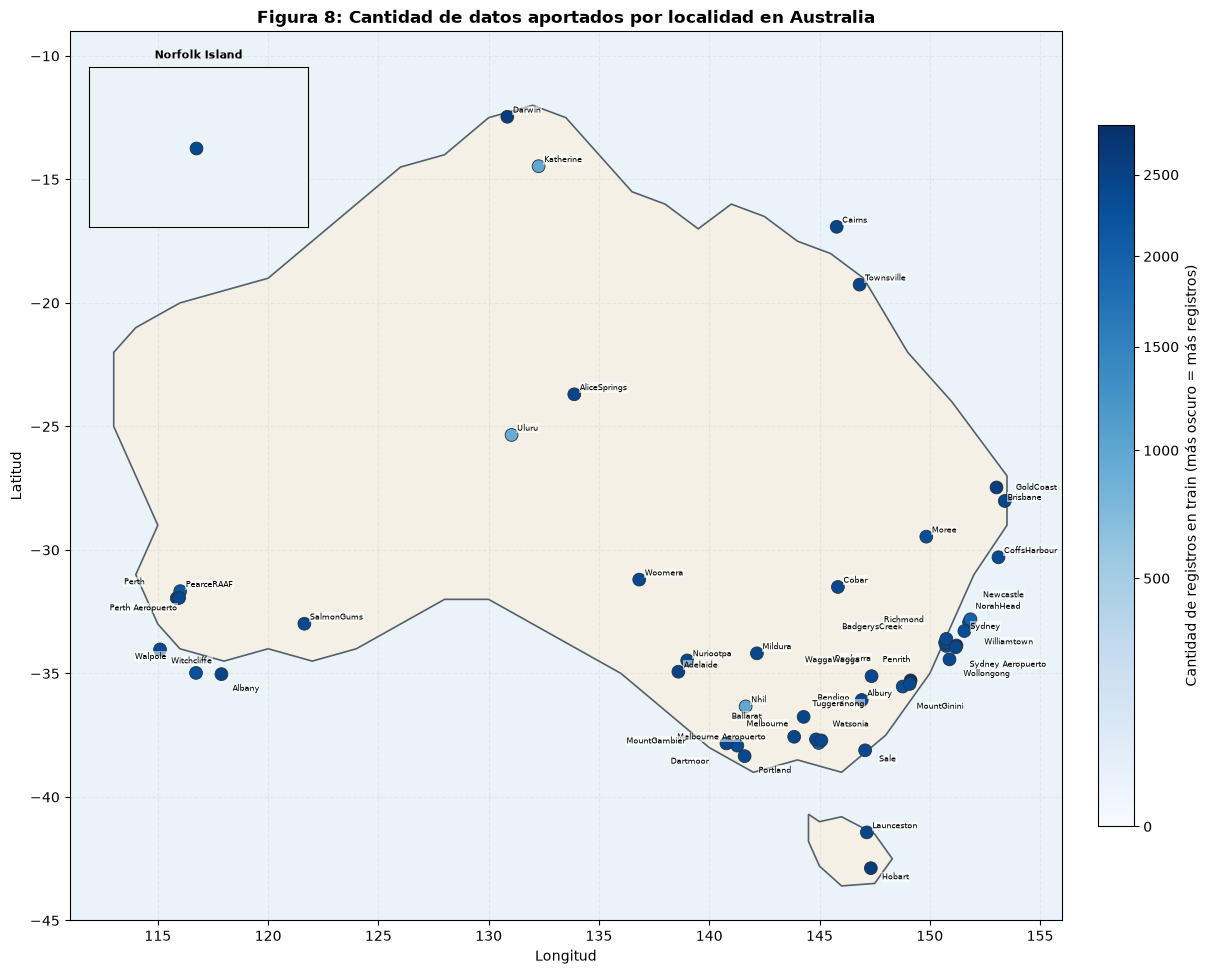

In [25]:
coordenadas_localidades = {
    "Adelaide": (-34.9285, 138.6007),
    "Albany": (-35.0275, 117.8840),
    "Albury": (-36.0737, 146.9135),
    "AliceSprings": (-23.6980, 133.8807),
    "BadgerysCreek": (-33.8828, 150.7445),
    "Ballarat": (-37.5622, 143.8503),
    "Bendigo": (-36.7570, 144.2794),
    "Brisbane": (-27.4698, 153.0251),
    "Cairns": (-16.9186, 145.7781),
    "Canberra": (-35.2809, 149.1300),
    "Cobar": (-31.4983, 145.8344),
    "CoffsHarbour": (-30.2963, 153.1135),
    "Dartmoor": (-37.9222, 141.2743),
    "Darwin": (-12.4634, 130.8456),
    "GoldCoast": (-28.0167, 153.4000),
    "Hobart": (-42.8821, 147.3272),
    "Katherine": (-14.4652, 132.2635),
    "Launceston": (-41.4332, 147.1448),
    "Melbourne": (-37.8136, 144.9631),
    "MelbourneAirport": (-37.6690, 144.8410),
    "Mildura": (-34.1855, 142.1625),
    "Moree": (-29.4617, 149.8416),
    "MountGambier": (-37.8318, 140.7792),
    "MountGinini": (-35.5294, 148.7728),
    "Newcastle": (-32.9283, 151.7817),
    "Nhil": (-36.3333, 141.6500),
    "NorahHead": (-33.2817, 151.5675),
    "NorfolkIsland": (-29.0408, 167.9547),
    "Nuriootpa": (-34.4721, 139.0010),
    "PearceRAAF": (-31.6675, 116.0150),
    "Penrith": (-33.7511, 150.6942),
    "Perth": (-31.9505, 115.8605),
    "PerthAirport": (-31.9403, 115.9669),
    "Portland": (-38.3460, 141.6042),
    "Richmond": (-33.5995, 150.7510),
    "Sale": (-38.1109, 147.0680),
    "SalmonGums": (-32.9867, 121.6436),
    "Sydney": (-33.8688, 151.2093),
    "SydneyAirport": (-33.9399, 151.1753),
    "Townsville": (-19.2589, 146.8169),
    "Tuggeranong": (-35.4244, 149.0888),
    "Uluru": (-25.3444, 131.0369),
    "WaggaWagga": (-35.1082, 147.3598),
    "Walpole": (-34.9774, 116.7310),
    "Watsonia": (-37.7104, 145.0836),
    "Williamtown": (-32.8069, 151.8428),
    "Witchcliffe": (-34.0267, 115.1000),
    "Wollongong": (-34.4278, 150.8931),
    "Woomera": (-31.1999, 136.8259),
}


# Contornos simplificados para mostrar Australia continental y Tasmania sin dependencias geográficas externas.
contorno_australia = np.array([
    [113.0, -22.0], [114.0, -21.0], [116.0, -20.0], [118.0, -19.5],
    [120.0, -19.0], [122.0, -17.5], [124.0, -16.0], [126.0, -14.5],
    [128.0, -14.0], [130.0, -12.5], [132.0, -12.0], [133.5, -12.5],
    [135.0, -14.0], [136.5, -15.5], [138.0, -16.0], [139.5, -17.0],
    [141.0, -16.0], [142.5, -16.5], [144.0, -17.5], [145.5, -18.0],
    [147.0, -19.0], [149.0, -22.0], [151.0, -24.0], [153.5, -27.0],
    [153.5, -29.0], [152.0, -31.0], [151.0, -33.0], [150.0, -35.0],
    [148.0, -37.5], [146.0, -39.0], [144.0, -38.5], [142.0, -39.0],
    [140.0, -38.0], [138.0, -36.5], [136.0, -35.0], [134.0, -34.0],
    [132.0, -33.0], [130.0, -32.0], [128.0, -32.0], [126.0, -33.0],
    [124.0, -34.0], [122.0, -34.5], [120.0, -34.0], [118.0, -34.5],
    [116.0, -34.0], [115.0, -33.0], [114.0, -31.0], [115.0, -29.0],
    [114.0, -27.0], [113.0, -25.0], [113.0, -22.0],
])
contorno_tasmania = np.array([
    [144.5, -40.7], [145.0, -41.0], [146.0, -40.8], [147.5, -41.5],
    [148.3, -42.5], [147.5, -43.5], [146.0, -43.6], [145.0, -42.8],
    [144.5, -41.8], [144.5, -40.7],
])

conteo_localidades_mapa = X_train["Location"].value_counts()
localidades_mapa = sorted(conteo_localidades_mapa.index)
localidades_sin_coordenadas = sorted(set(localidades_mapa) - set(coordenadas_localidades))
if localidades_sin_coordenadas:
    raise ValueError(f"Faltan coordenadas para localidades de train: {localidades_sin_coordenadas}")

longitudes_mapa = np.array([coordenadas_localidades[localidad][1] for localidad in localidades_mapa])
latitudes_mapa = np.array([coordenadas_localidades[localidad][0] for localidad in localidades_mapa])
registros_mapa = conteo_localidades_mapa.loc[localidades_mapa].to_numpy()

fig, ax = plt.subplots(figsize=(13, 10))
ax.set_facecolor("#eaf4f8")
for contorno in (contorno_australia, contorno_tasmania):
    ax.fill(contorno[:, 0], contorno[:, 1], facecolor="#f4f0e5", edgecolor="#52616b", linewidth=1.2, zorder=1)

norma_color = PowerNorm(gamma=0.6, vmin=0, vmax=registros_mapa.max())
mascara_continente = np.array([localidad != "NorfolkIsland" for localidad in localidades_mapa])
if not mascara_continente.any():
    raise ValueError("No hay localidades continentales para representar en el mapa.")
puntos = ax.scatter(
    longitudes_mapa[mascara_continente], latitudes_mapa[mascara_continente],
    c=registros_mapa[mascara_continente], cmap="Blues", norm=norma_color,
    s=85, edgecolors="#263238", linewidths=0.6, zorder=3,
)

# Desplazamientos para que se lean mejor las etiquetas de localidades cercanas.
desplazamientos_etiquetas = {
    "Sydney": (10, 12), "SydneyAirport": (10, -14), "BadgerysCreek": (-75, 12),
    "Penrith": (-45, -14), "Richmond": (-45, 12), "Wollongong": (10, -12),
    "NorahHead": (8, 16), "Newcastle": (10, 18), "Williamtown": (10, -18),
    "Canberra": (-55, 14), "Tuggeranong": (-70, -16), "MountGinini": (10, -16),
    "WaggaWagga": (-48, 10), "Melbourne": (-52, 12), "MelbourneAirport": (-100, 0),
    "Watsonia": (8, 10), "Ballarat": (-45, 13), "Bendigo": (10, 12),
    "MountGambier": (-72, 0), "Portland": (10, -12), "Dartmoor": (-48, -13),
    "Sale": (10, -8), "Perth": (-38, 10), "PerthAirport": (-50, -9),
    "Albany": (8, -12), "Walpole": (-44, 10), "Witchcliffe": (8, -10),
    "GoldCoast": (8, 8), "Brisbane": (8, -9), "Hobart": (8, -8),
}
for localidad, longitud, latitud in zip(localidades_mapa, longitudes_mapa, latitudes_mapa):
    if localidad != "NorfolkIsland":
        desplazamiento = desplazamientos_etiquetas.get(localidad, (4, 3))
        ax.annotate(
            localidad.replace("Airport", " Aeropuerto"), (longitud, latitud),
            xytext=desplazamiento, textcoords="offset points", fontsize=5.5,
            bbox={"facecolor": "white", "alpha": 0.55, "edgecolor": "none", "pad": 0.5},
            zorder=4,
        )

barra_color = fig.colorbar(puntos, ax=ax, shrink=0.75, pad=0.03)
barra_color.set_label("Cantidad de registros en train (más oscuro = más registros)")
ax.set_title(f"Figura {N_FIG}: Cantidad de datos aportados por localidad en Australia", fontweight="bold")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_xlim(111, 156)
ax.set_ylim(-45, -9)
ax.set_aspect(1.12)
ax.grid(alpha=0.2, linestyle="--")

# Norfolk Island queda fuera de la escala continental; se muestra en un recuadro.
if "NorfolkIsland" in conteo_localidades_mapa.index:
    ax_inset = ax.inset_axes([0.02, 0.78, 0.22, 0.18])
    ax_inset.set_facecolor("#eaf4f8")
    ax_inset.scatter(
        [coordenadas_localidades["NorfolkIsland"][1]],
        [coordenadas_localidades["NorfolkIsland"][0]],
        c=[conteo_localidades_mapa["NorfolkIsland"]], cmap="Blues", norm=norma_color,
        s=85, edgecolors="#263238", linewidths=0.6,
    )
    ax_inset.set_xlim(166, 170)
    ax_inset.set_ylim(-31, -27)
    ax_inset.set_title("Norfolk Island", fontsize=8, fontweight="bold")
    ax_inset.set_xticks([])
    ax_inset.set_yticks([])
    ax_inset.grid(alpha=0.2)

N_FIG += 1
plt.tight_layout()
plt.show()

Análisis de la Figura 8: El mapa muestra la distribución geográfica de las 49 estaciones meteorológicas incluidas en train y la cantidad de registros aportados por cada una. La cobertura se extiende por distintas regiones de Australia, pero las estaciones no están repartidas uniformemente: hay una concentración visible en el sudeste y en la costa este, mientras que el interior y algunas zonas del oeste tienen menos estaciones. Canberra y Sydney aportan las mayores cantidades (aproximadamente 2.800 y 2.700 registros); Uluru es la que menos aporta, con alrededor de 900. Norfolk Island se muestra aparte porque queda fuera de la escala del mapa continental.

Este gráfico describe dónde y con qué frecuencia se tomaron observaciones; no indica qué localidades son más lluviosas, porque el color representa cantidad de registros y no la proporción de RainTomorrow = Yes. La cobertura desigual implica que el modelo verá más ejemplos de algunas estaciones y regiones que de otras, por lo que el desempeño global podría reflejar en mayor medida las zonas con más observaciones. También da contexto a la imputación espacial de la sección 6: hay estaciones cercanas en algunas áreas, pero las estaciones del interior o de zonas con menor cobertura pueden tener menos vecinos comparables. Las coordenadas son aproximadas y el contorno del país es esquemático, así que el mapa es adecuado para una visión general, no para medir distancias geográficas precisas.

## 5.7. Matriz de correlación de Spearman y gráficos de dispersión

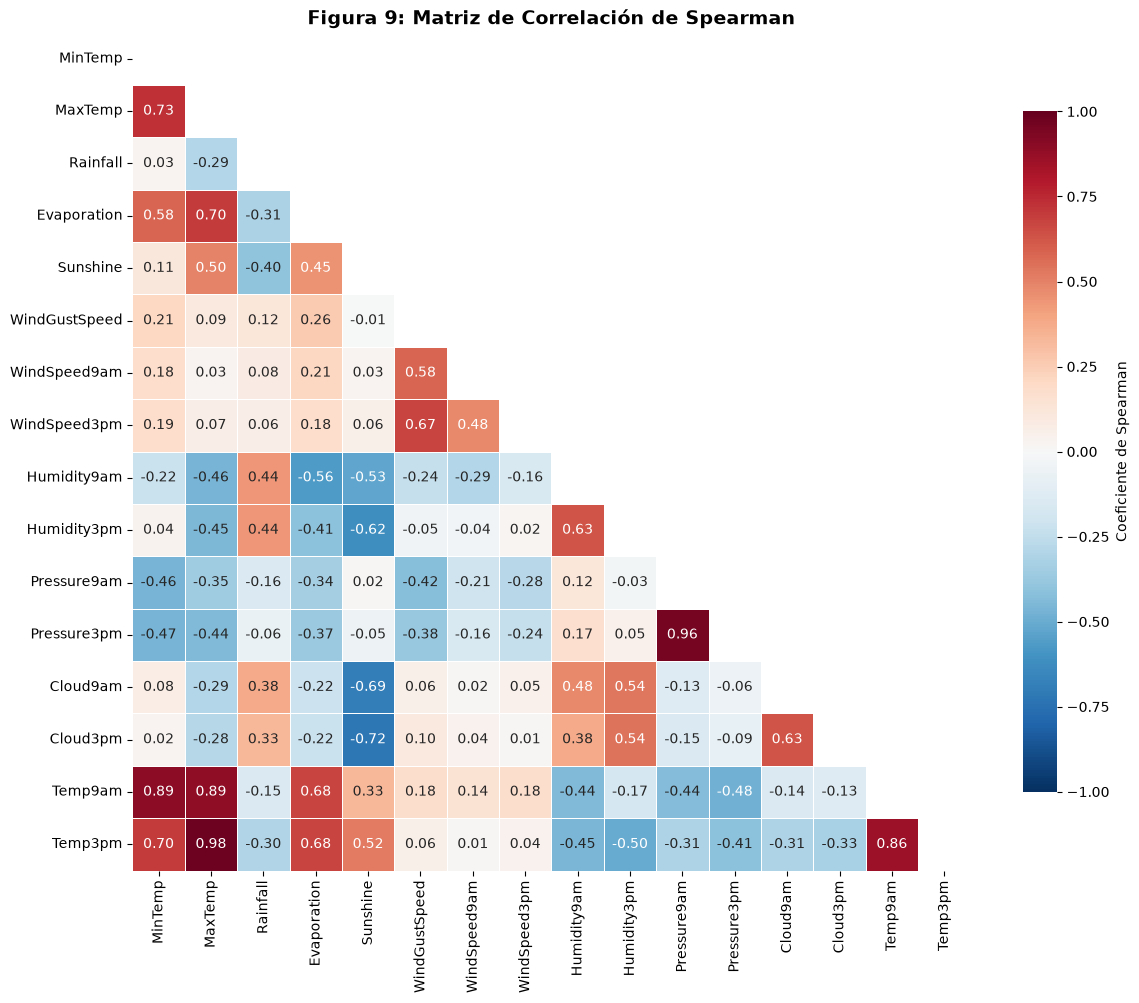

In [26]:
# Matriz de correlación de Spearman (solo variables numéricas)
corr_spearman = X_train.corr(method='spearman', numeric_only=True)

mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_spearman, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Coeficiente de Spearman'})
ax.set_title(f'Figura {N_FIG}: Matriz de Correlación de Spearman', fontsize=14, fontweight='bold')
N_FIG += 1
plt.tight_layout()
plt.show()

En la matriz de Spearman se resumen asociaciones monotónicas entre los predictores. Se destacan MaxTemp–Temp3pm (0,98), Pressure9am–Pressure3pm (0,96), MinTemp–Temp9am (0,89), MaxTemp–Temp9am (0,89) y Temp9am–Temp3pm (0,86). Estas asociaciones altas sugieren redundancia y posible multicolinealidad si se incluyen simultáneamente en la regresión logística.

También aparecen relaciones inversas apreciables pero de menor magnitud, por ejemplo Sunshine–Cloud3pm (-0,72) y Sunshine–Cloud9am (-0,69), además de relaciones moderadas entre las velocidades del viento. Las figuras de dispersión siguientes permiten revisar la forma de algunas de estas relaciones y cómo se distribuyen las clases de RainTomorrow.

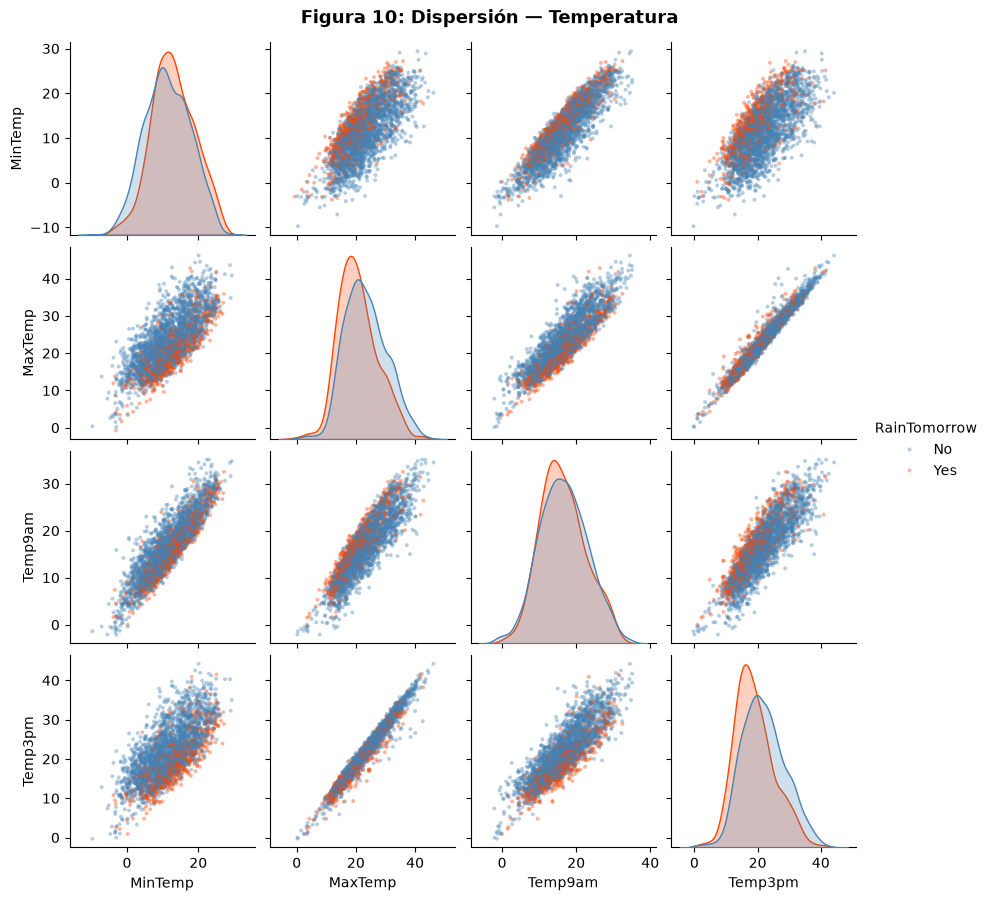

In [27]:
# Muestra aleatoria de train para que el gráfico sea liviano y legible
N_MUESTRA = 3000

datos_scatter = X_train[cols_numericas].copy()
datos_scatter["RainTomorrow"] = y_train          # alineado por índice
muestra = datos_scatter.sample(N_MUESTRA, random_state=RANDOM_STATE)

variables = ['MinTemp', 'MaxTemp', 'Temp9am', 'Temp3pm']
g = sns.pairplot(
    muestra, vars=variables, hue="RainTomorrow", hue_order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "orangered"},
    diag_kind="kde", plot_kws=dict(s=8, alpha=0.4, edgecolor="none"),
    diag_kws=dict(common_norm=False, fill=True), height=2.2,
)
g.figure.suptitle(f"Figura {N_FIG}: Dispersión — Temperatura", fontsize=13, fontweight="bold", y=1.02)
N_FIG += 1
plt.show()


La Figura 10 muestra asociaciones positivas claras entre las temperaturas mínimas y de las 9:00, y entre las máximas y las de las 15:00. El vínculo MaxTemp–Temp3pm es especialmente estrecho, consistente con Spearman (0,98); MinTemp–Temp9am también presenta una tendencia marcada (0,89). Temp9am se asocia tanto con MinTemp como con MaxTemp, y Temp9am–Temp3pm también muestra una tendencia positiva. Los puntos de las clases Yes y No se superponen ampliamente, aunque hay diferencias de distribución; por sí sola, esta figura no permite establecer una regla de clasificación ni causalidad.

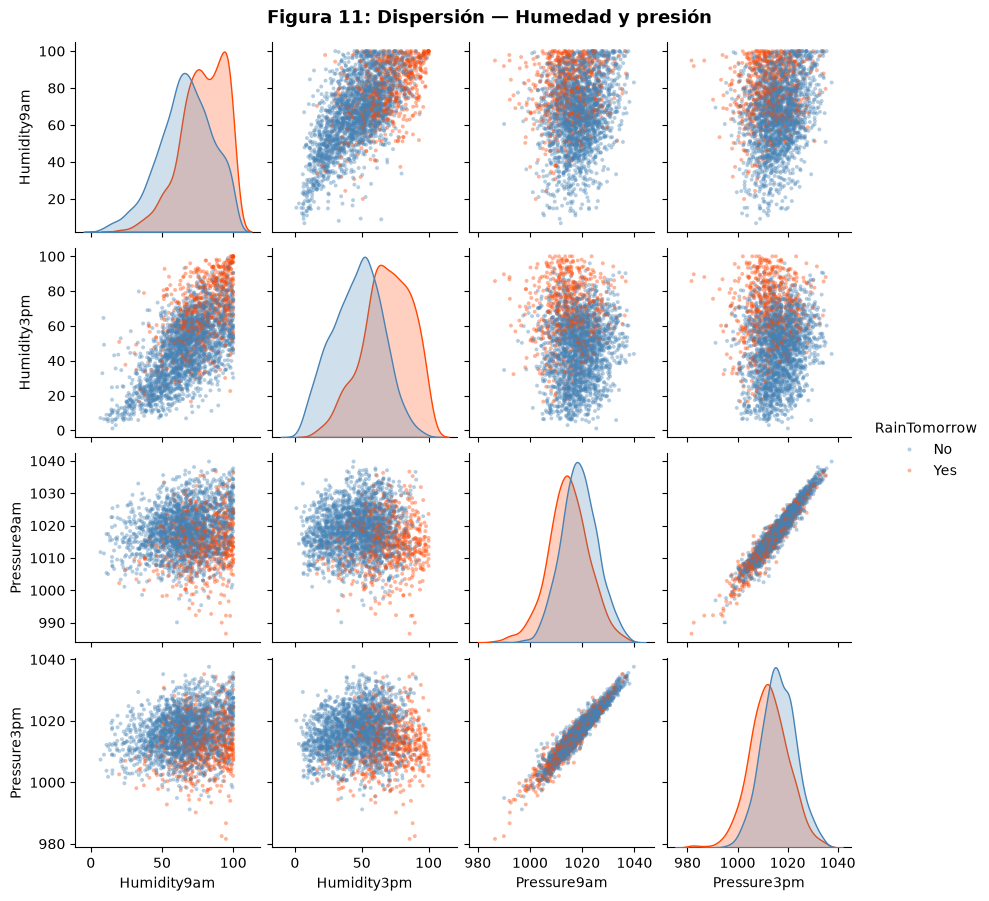

In [28]:
# Muestra aleatoria de train para que el gráfico sea liviano y legible
N_MUESTRA = 3000

datos_scatter = X_train[cols_numericas].copy()
datos_scatter["RainTomorrow"] = y_train          # alineado por índice
muestra = datos_scatter.sample(N_MUESTRA, random_state=RANDOM_STATE)

variables = ['Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm']
g = sns.pairplot(
    muestra, vars=variables, hue="RainTomorrow", hue_order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "orangered"},
    diag_kind="kde", plot_kws=dict(s=8, alpha=0.4, edgecolor="none"),
    diag_kws=dict(common_norm=False, fill=True), height=2.2,
)
g.figure.suptitle(f"Figura {N_FIG}: Dispersión — Humedad y presión", fontsize=13, fontweight="bold", y=1.02)
N_FIG += 1
plt.show()


En la Figura 11, Pressure9am y Pressure3pm forman una banda casi lineal, en concordancia con su correlación de Spearman de 0,96, ambas variables aportan información muy similar. Humidity9am y Humidity3pm muestran una asociación positiva, pero con dispersión considerable. Las relaciones entre humedad y presión son mucho menos definidas. Hay cierto desplazamiento de las distribuciones por clase, pero una superposición importante entre Yes y No; ninguna variable separa perfectamente el objetivo en este gráfico.

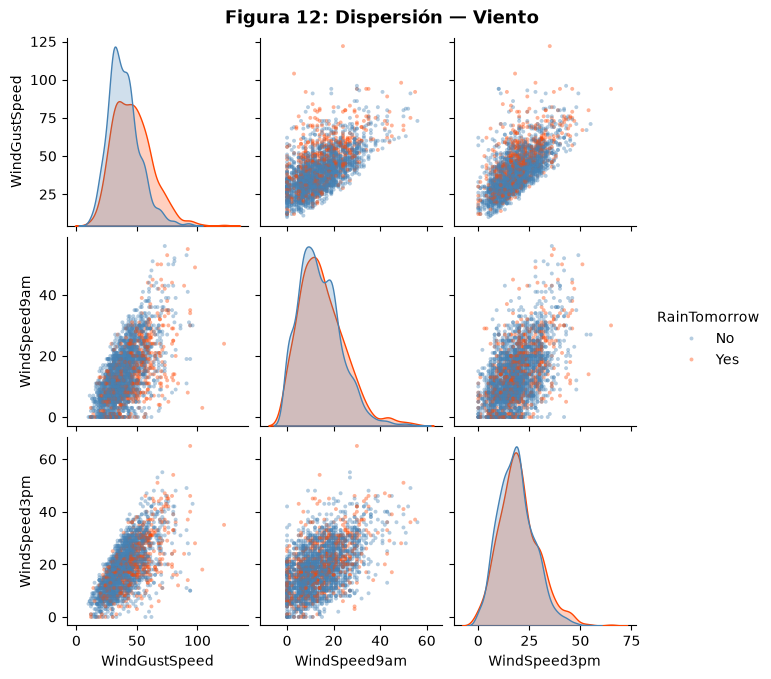

In [29]:
# Muestra aleatoria de train para que el gráfico sea liviano y legible
N_MUESTRA = 3000

datos_scatter = X_train[cols_numericas].copy()
datos_scatter["RainTomorrow"] = y_train          # alineado por índice
muestra = datos_scatter.sample(N_MUESTRA, random_state=RANDOM_STATE)

variables = ['WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm']
g = sns.pairplot(
    muestra, vars=variables, hue="RainTomorrow", hue_order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "orangered"},
    diag_kind="kde", plot_kws=dict(s=8, alpha=0.4, edgecolor="none"),
    diag_kws=dict(common_norm=False, fill=True), height=2.2,
)
g.figure.suptitle(f"Figura {N_FIG}: Dispersión — Viento", fontsize=13, fontweight="bold", y=1.02)
N_FIG += 1
plt.show()


La Figura 12 muestra relaciones positivas entre WindGustSpeed y las velocidades registradas a las 9:00 y 15:00, y una asociación más moderada entre WindSpeed9am y WindSpeed3pm. Los puntos están más dispersos que en los pares de temperatura y presión, por lo que la redundancia es menos extrema. Las distribuciones de RainTomorrow se superponen ampliamente; pueden existir diferencias entre clases, pero el gráfico no respalda una separación nítida.

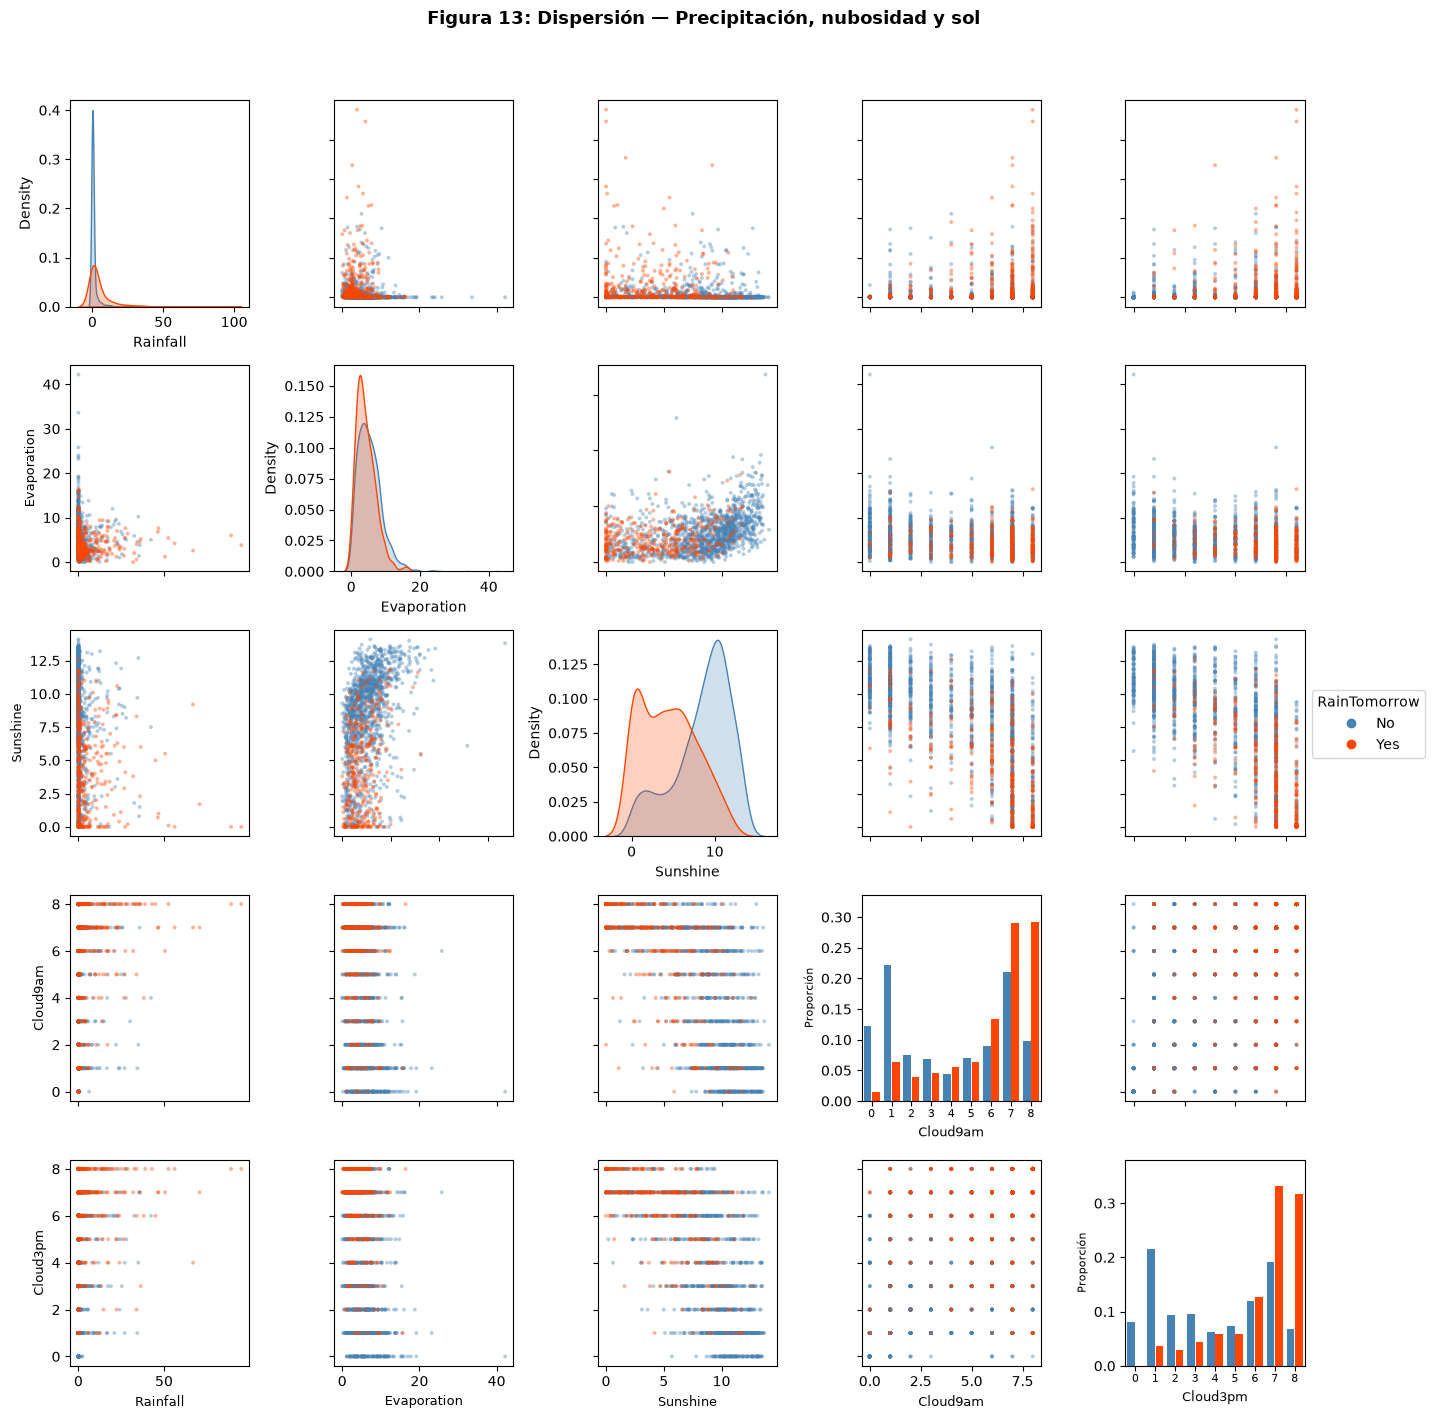

In [30]:
# Muestra aleatoria de train para que el gráfico sea liviano y legible
N_MUESTRA = 3000

datos_scatter = X_train[cols_numericas].copy()
datos_scatter["RainTomorrow"] = y_train
muestra = datos_scatter.sample(N_MUESTRA, random_state=RANDOM_STATE)

variables = ['Rainfall', 'Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm']
clases = ["No", "Yes"]
paleta = {"No": "steelblue", "Yes": "orangered"}
fig, axes = plt.subplots(len(variables), len(variables), figsize=(14, 14))

for i, variable_y in enumerate(variables):
    for j, variable_x in enumerate(variables):
        ax = axes[i, j]
        if i == j and variable_x in ["Cloud9am", "Cloud3pm"]:
            niveles = np.arange(9)
            ancho = 0.38
            max_proporcion = 0
            for k, clase in enumerate(clases):
                proporciones = (
                    muestra.loc[muestra["RainTomorrow"] == clase, variable_x]
                    .value_counts(normalize=True)
                    .reindex(niveles, fill_value=0)
                )
                max_proporcion = max(max_proporcion, proporciones.max())
                ax.bar(
                    niveles + (k - 0.5) * 0.42,
                    proporciones.to_numpy(),
                    width=ancho,
                    color=paleta[clase],
                )
            ax.set_xlim(-0.5, 8.5)
            ax.set_ylim(0, max_proporcion * 1.15)
            ax.set_xticks(niveles)
            ax.set_xlabel(variable_x, fontsize=9)
            ax.set_ylabel("Proporción", fontsize=8)
            ax.tick_params(axis="x", labelsize=8, rotation=0, pad=2)
        elif i == j:
            for clase in clases:
                valores = muestra.loc[muestra["RainTomorrow"] == clase, variable_x].dropna()
                sns.kdeplot(x=valores, ax=ax, color=paleta[clase], fill=True, common_norm=False)
        else:
            for clase in clases:
                datos_clase = muestra[muestra["RainTomorrow"] == clase]
                ax.scatter(
                    datos_clase[variable_x], datos_clase[variable_y],
                    s=8, alpha=0.4, color=paleta[clase], edgecolors="none",
                )

        if i != j:
            if i == len(variables) - 1:
                ax.set_xlabel(variable_x, fontsize=9)
            else:
                ax.tick_params(axis="x", labelbottom=False)
            if j == 0:
                ax.set_ylabel(variable_y, fontsize=9)
            else:
                ax.tick_params(axis="y", labelleft=False)

fig.legend(
    handles=[plt.Line2D([0], [0], marker="o", linestyle="", color=paleta[clase], label=clase) for clase in clases],
    title="RainTomorrow", loc="center right", bbox_to_anchor=(1.02, 0.5),
)
fig.suptitle(f"Figura {N_FIG}: Dispersión — Precipitación, nubosidad y sol", fontsize=13, fontweight="bold", y=1.01)
fig.tight_layout(rect=[0, 0, 0.94, 0.98])
N_FIG += 1
plt.show()


La Figura 13 muestra que Rainfall se concentra cerca de cero, con una cola hacia valores altos. En el gráfico de dispersión, los valores más elevados aparecen con mayor frecuencia para RainTomorrow = Yes, aunque hay superposición entre clases es una asociación descriptiva y no una regla determinista. Evaporation también presenta una distribución asimétrica y una relación dispersa con Sunshine.

En los paneles de Sunshine frente a Cloud9am y Cloud3pm se observa una tendencia general a menos horas de sol con mayor nubosidad, más marcada para Cloud3pm. Cloud9am y Cloud3pm tienden a aumentar conjuntamente, pero los valores discretos generan bandas y existe dispersión. En las diagonales, los gráficos de barras comparan las proporciones de cada nivel de nubosidad dentro de cada clase, se observa que RainTomorrow = Yes concentra relativamente más observaciones en niveles altos de nubosidad, mientras que No tiene mayor presencia relativa en varios niveles bajos; las diferencias no son absolutas y hay niveles compartidos por ambas clases.

### Conclusión: reducción de colinealidad antes de la regresión logística

En conjunto, la matriz y las Figuras entre 10 y 13 muestran que algunas variables miden condiciones muy parecidas: MaxTemp con Temp3pm, MinTemp con Temp9am y Pressure9am con Pressure3pm. Para reducir redundancia entre predictores y facilitar la interpretación y estabilidad de los coeficientes de la regresión logística, se decidió conservar MaxTemp, MinTemp y Pressure3pm, y eliminar Temp3pm, Temp9am y Pressure9am, respectivamente.

In [31]:
# Eliminamos los predictores redundantes identificados en la matriz de Spearman.
variables_colineales = ["Temp3pm", "Temp9am", "Pressure9am"]
for conjunto in (train, test, X_train, X_test):
    conjunto.drop(columns=variables_colineales, inplace=True)

cols_numericas = [col for col in cols_numericas if col not in variables_colineales]
cols_continuas = [col for col in cols_continuas if col not in variables_colineales]

assert all(col not in X_train.columns for col in variables_colineales)
assert all(col not in X_test.columns for col in variables_colineales)
print(f"Predictores eliminados: {variables_colineales}")
print(f"Columnas restantes: {X_train.shape[1]} en train y {X_test.shape[1]} en test.")

Predictores eliminados: ['Temp3pm', 'Temp9am', 'Pressure9am']
Columnas restantes: 19 en train y 19 en test.


# 6. Imputación espacial por KNN 

Para cada valor faltante buscamos las 5 estaciones geográficamente más cercanas con una observación disponible de esa variable en la misma fecha. Usamos la mediana para variables numéricas y la moda para variables categóricas. En Cloud9am y Cloud3pm, redondear la mediana conserva la naturaleza discreta de la escala de octas. La elección es razonable para datos meteorológicos porque estaciones cercanas y observaciones del mismo día pueden compartir condiciones atmosféricas, y la mediana reduce la influencia de un vecino con un valor extremo. La validación oculta el 10% de los valores observados de train. En test, la imputación usa únicamente predictores observados de otras estaciones meteorológicas de esa misma fecha, es una evaluación transductiva, válida si al predecir se dispone de las observaciones del resto de las estaciones para ese día. Nunca se utilizan RainTomorrow ni fechas futuras para imputar.

,Variable,Métrica,Valores ocultados,Casos evaluables,Cobertura (%),Resultado
0,MinTemp,MAE,11323,11311,99.894,2.806
1,MaxTemp,MAE,11348,11333,99.868,2.749
2,Rainfall,MAE,11257,11249,99.929,2.098
3,Evaporation,MAE,6936,6915,99.697,1.905
4,Sunshine,MAE,6518,6502,99.755,2.350
5,WindGustDir,Exactitud,10597,10576,99.802,0.183
6,WindGustSpeed,MAE,10603,10583,99.811,8.628
7,WindDir9am,Exactitud,10531,10511,99.810,0.187
8,WindDir3pm,Exactitud,11126,11118,99.928,0.198
9,WindSpeed9am,MAE,11250,11238,99.893,6.904


,Conjunto,Variable,Nulos antes,Imputados,Nulos después
0,Train,MinTemp,468,468,0
1,Train,MaxTemp,223,223,0
2,Train,Rainfall,1127,1127,0
3,Train,Evaporation,44334,44334,0
4,Train,Sunshine,48513,48513,0
5,Train,WindGustDir,7731,7727,4
6,Train,WindGustSpeed,7671,7669,2
7,Train,WindDir9am,8385,8383,2
8,Train,WindDir3pm,2436,2436,0
9,Train,WindSpeed9am,1203,1203,0


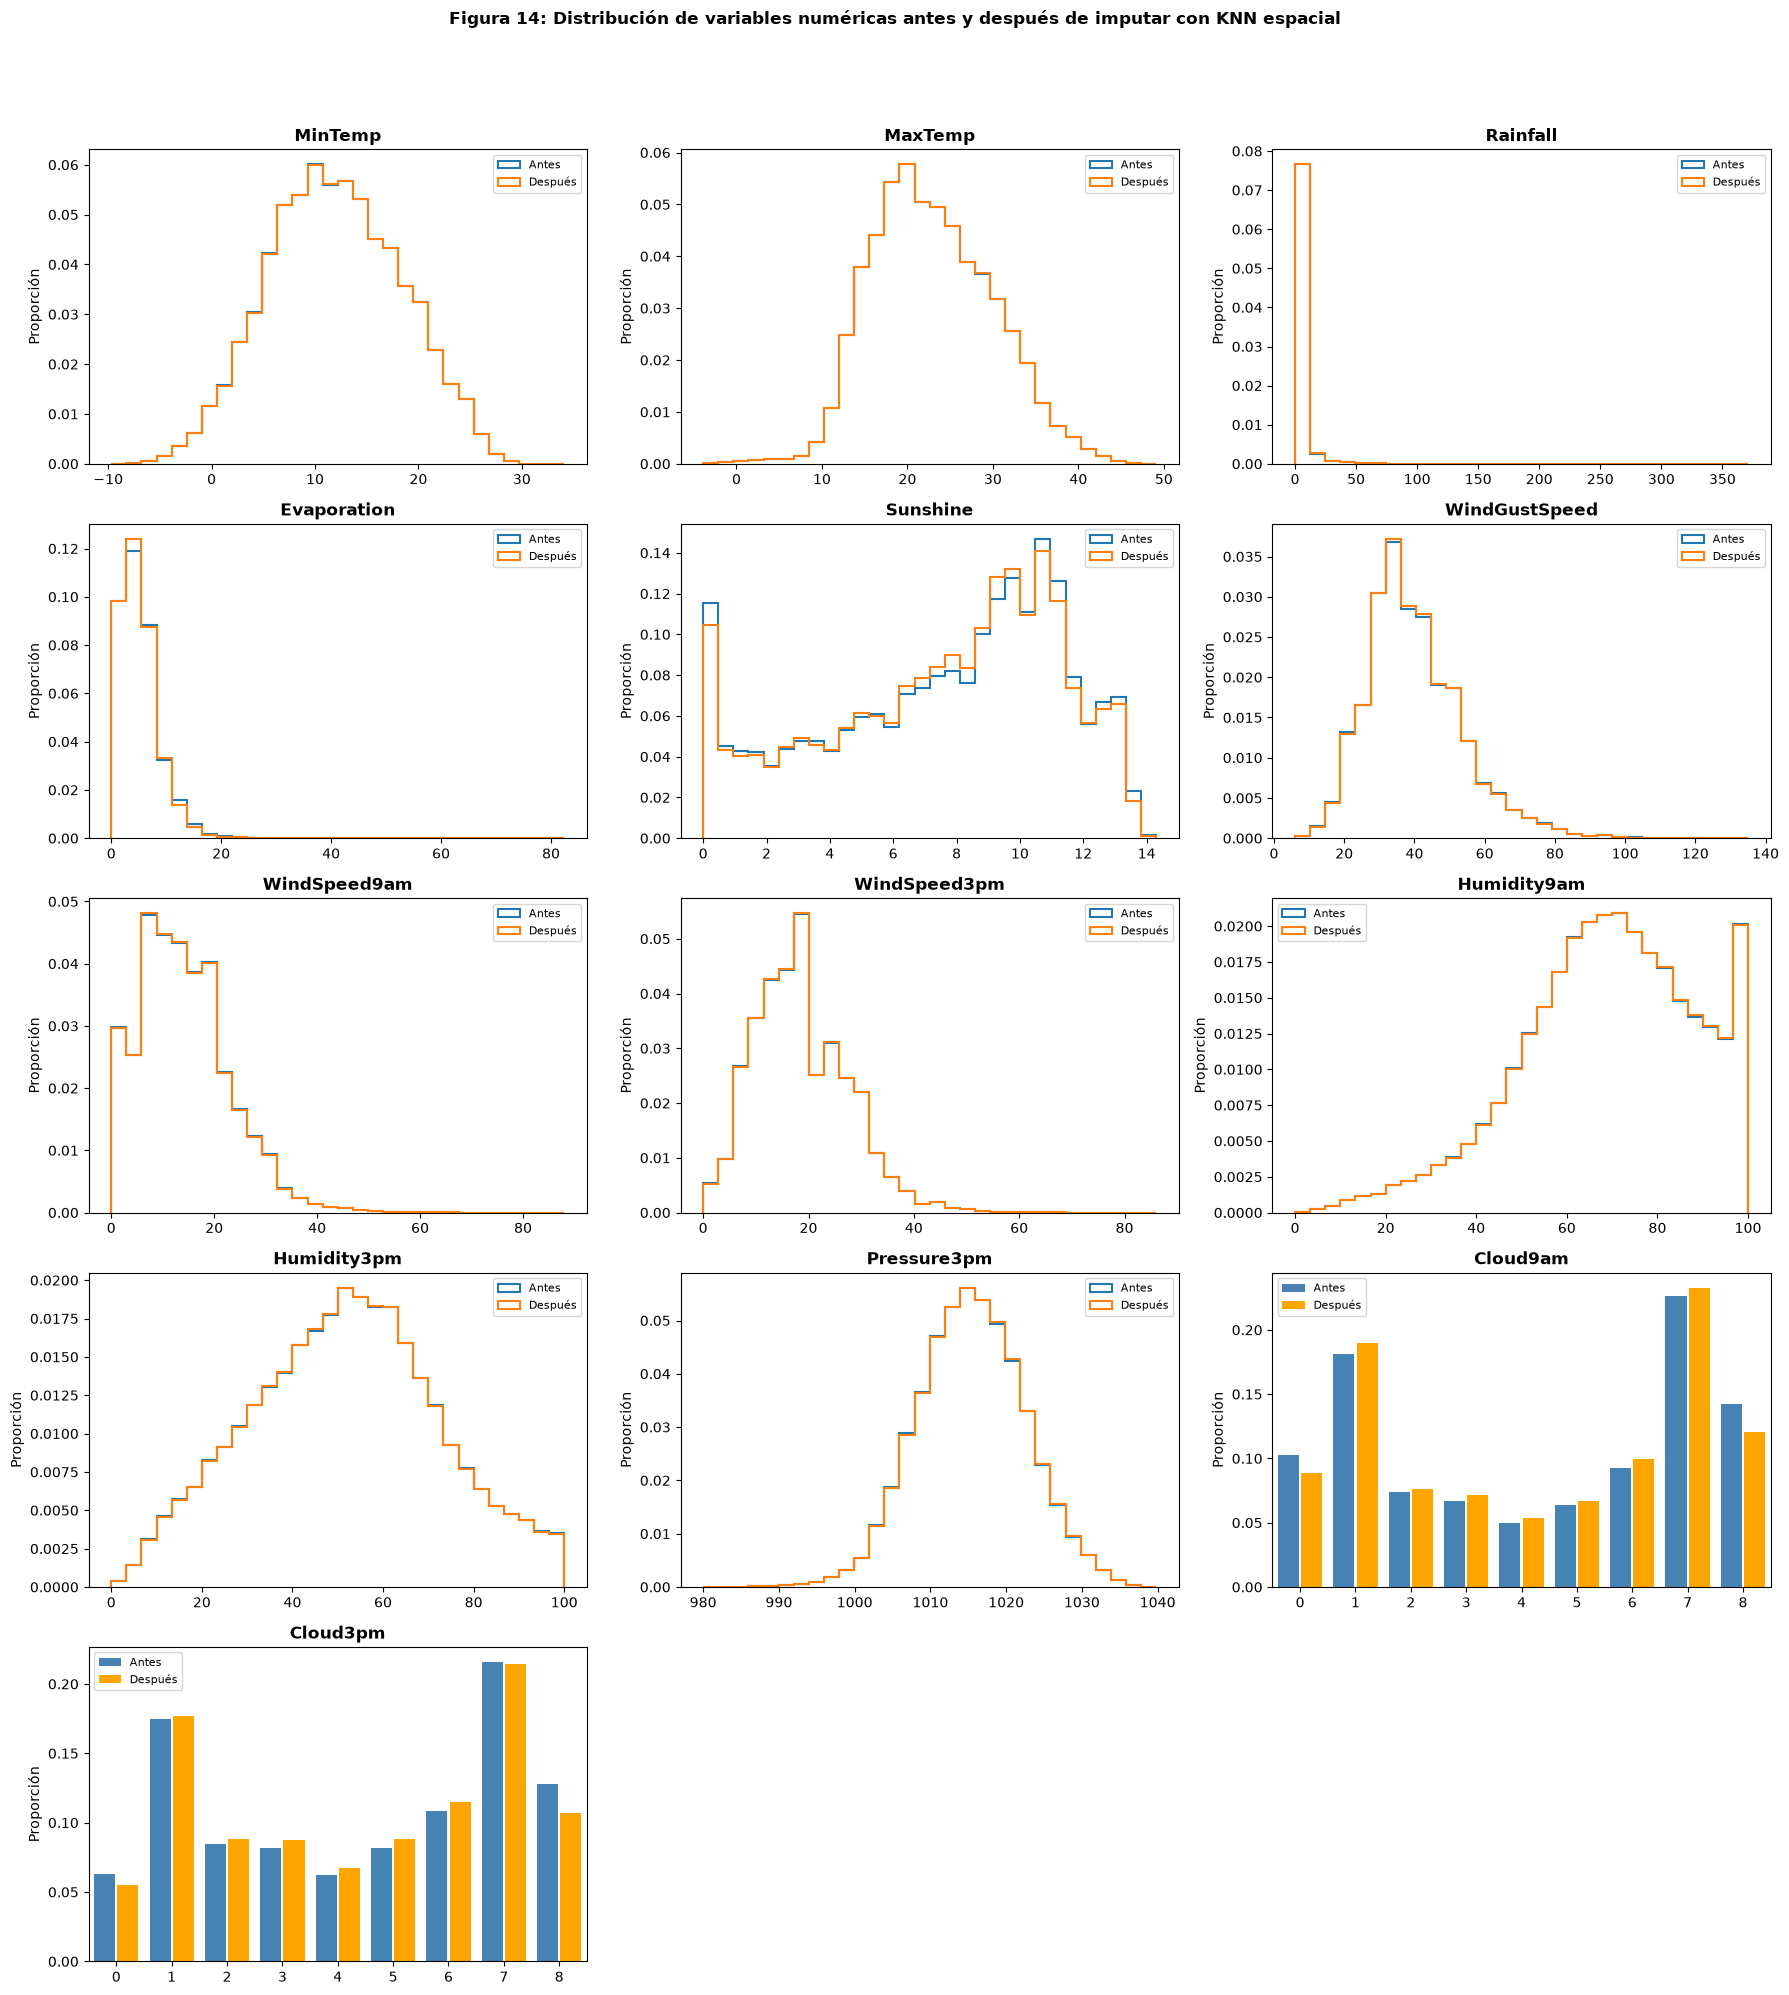

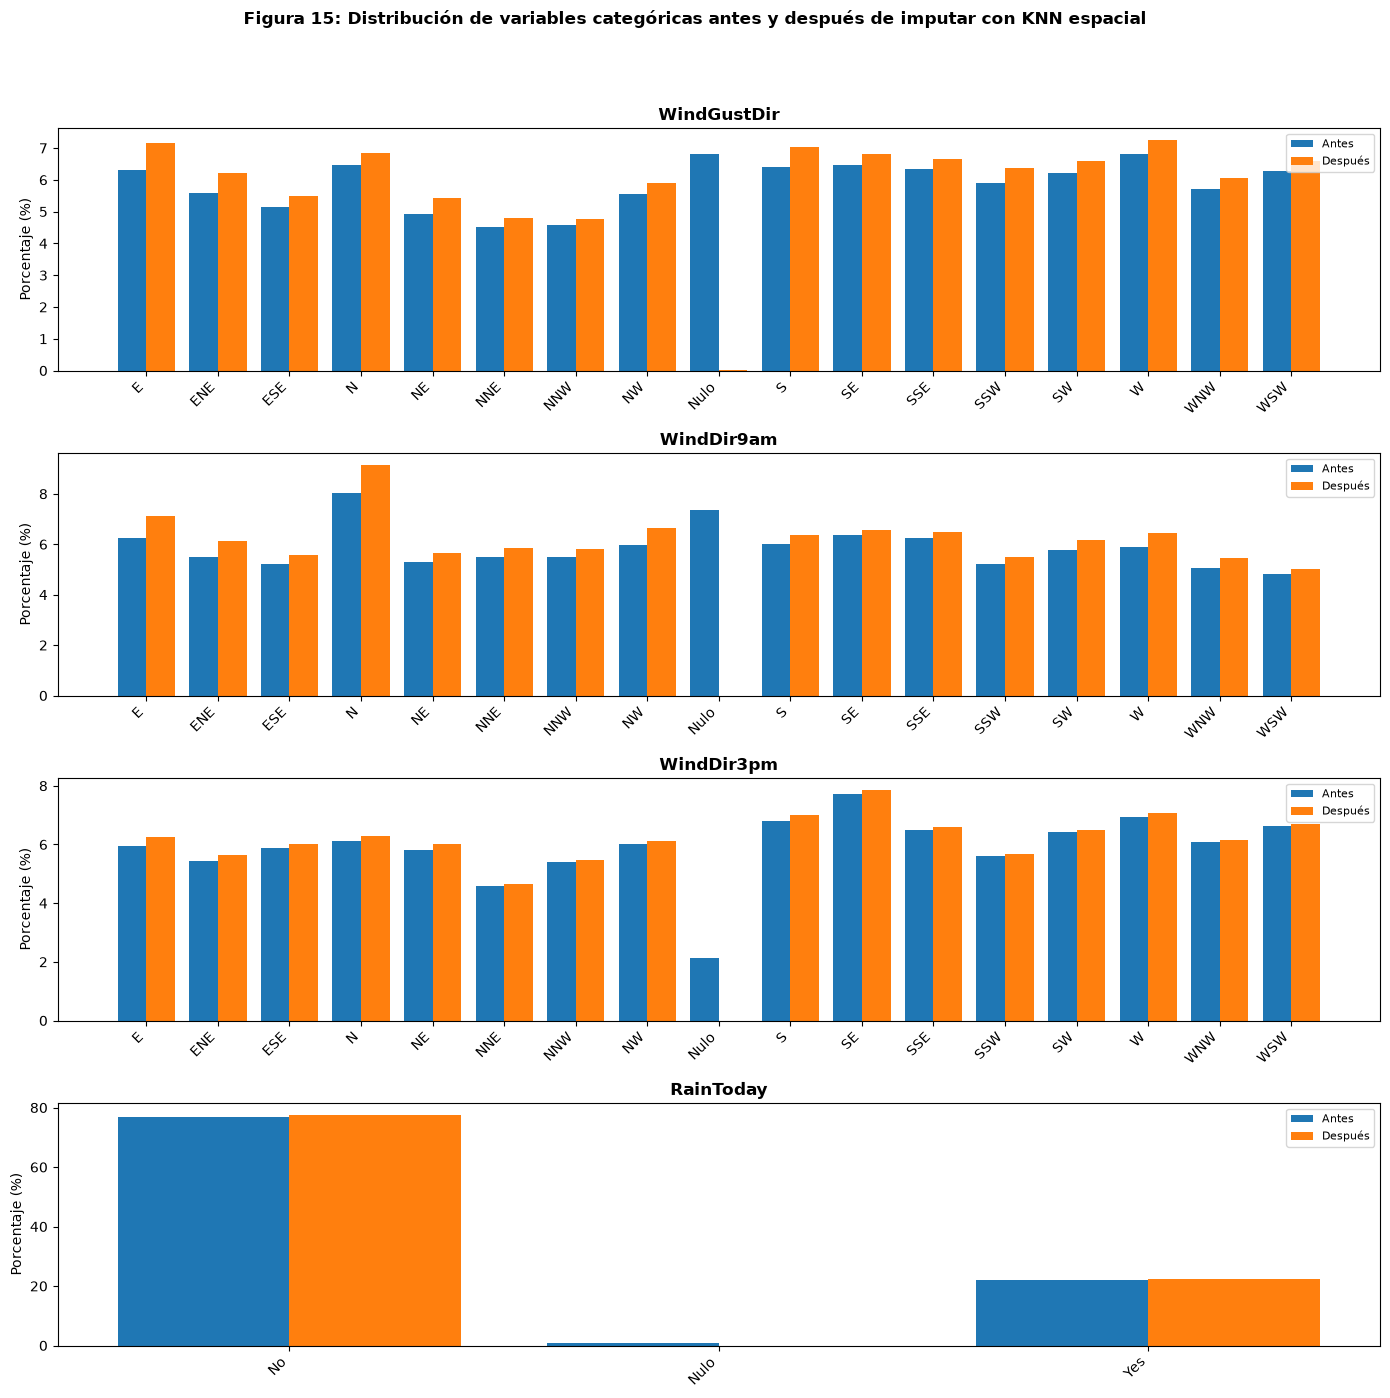

Luego de imputar: train=113,698 filas; test=28,452 filas.
Filas que todavía tienen algún nulo: train=6; test=0.


In [32]:
cols_cloud = ["Cloud9am", "Cloud3pm"]
K_VECINOS_ESPACIALES = 5
RADIO_TIERRA_KM = 6371.0088

train_knn = train.loc[train["RainTomorrow"].notna()].copy()
test_knn = test.loc[test["RainTomorrow"].notna()].copy()
y_train_knn = train_knn["RainTomorrow"].copy()
y_test_knn = test_knn["RainTomorrow"].copy()
X_train_knn = train_knn.drop(columns="RainTomorrow").copy()
X_test_knn = test_knn.drop(columns="RainTomorrow").copy()

if X_train_knn.duplicated(["Date", "Location"]).any() or X_test_knn.duplicated(["Date", "Location"]).any():
    raise ValueError("KNN espacial requiere una sola observación por fecha y localidad.")
if X_train_knn.columns.tolist() != X_test_knn.columns.tolist():
    raise AssertionError("Train y test deben tener las mismas variables para KNN espacial.")

localidades_knn = sorted(set(X_train_knn["Location"]) | set(X_test_knn["Location"]))
localidades_sin_coordenadas = set(localidades_knn) - set(coordenadas_localidades)
if localidades_sin_coordenadas:
    raise ValueError(f"Faltan coordenadas para: {sorted(localidades_sin_coordenadas)}")

coordenadas_radianes = np.radians(
    np.array([coordenadas_localidades[localidad] for localidad in localidades_knn], dtype=float)
)
latitudes = coordenadas_radianes[:, 0]
longitudes = coordenadas_radianes[:, 1]
delta_latitud = latitudes[None, :] - latitudes[:, None]
delta_longitud = longitudes[None, :] - longitudes[:, None]
a_haversine = (
    np.sin(delta_latitud / 2) ** 2
    + np.cos(latitudes[:, None]) * np.cos(latitudes[None, :])
    * np.sin(delta_longitud / 2) ** 2
)
distancias_km = 2 * RADIO_TIERRA_KM * np.arcsin(np.sqrt(np.clip(a_haversine, 0, 1)))
orden_estaciones_vecinas = {
    localidad: [
        localidades_knn[indice]
        for indice in np.argsort(distancias_km[posicion])
        if localidades_knn[indice] != localidad
    ]
    for posicion, localidad in enumerate(localidades_knn)
}
columnas_numericas_knn = set(X_train_knn.select_dtypes(include=[np.number]).columns)
columnas_imputar_knn = [
    columna for columna in X_train_knn.columns
    if columna not in {"Date", "Location"}
]

def imputar_knn_espacial(datos, columnas):
    resultado = datos.copy()
    reporte = []

    for columna in columnas:
        nulos_antes = int(resultado[columna].isna().sum())
        if columna not in columnas_numericas_knn:
            resultado[columna] = resultado[columna].astype(object)

        for _, grupo_dia in datos.groupby("Date", sort=False):
            faltantes = grupo_dia.loc[grupo_dia[columna].isna(), "Location"]
            if faltantes.empty:
                continue
            observados = grupo_dia.loc[
                grupo_dia[columna].notna(), ["Location", columna]
            ]
            donantes = dict(zip(observados["Location"], observados[columna]))
            localidades_disponibles = set(donantes)
            if not localidades_disponibles:
                continue

            for indice, localidad in faltantes.items():
                vecinos = [
                    vecina for vecina in orden_estaciones_vecinas[localidad]
                    if vecina in localidades_disponibles
                ][:K_VECINOS_ESPACIALES]
                if not vecinos:
                    continue

                valores_vecinos = [donantes[vecina] for vecina in vecinos]
                if columna in columnas_numericas_knn:
                    estimacion = float(np.median(valores_vecinos))
                    if columna in cols_cloud:
                        estimacion = round(estimacion)
                else:
                    estimacion = pd.Series(valores_vecinos, dtype="object").mode().iloc[0]
                resultado.at[indice, columna] = estimacion

        nulos_despues = int(resultado[columna].isna().sum())
        reporte.append({
            "Variable": columna,
            "Nulos antes": nulos_antes,
            "Imputados": nulos_antes - nulos_despues,
            "Nulos después": nulos_despues,
        })

    return resultado, pd.DataFrame(reporte)

reporte_validacion_knn = []
for columna in columnas_imputar_knn:
    observados = X_train_knn[columna].dropna()
    if observados.empty:
        continue
    ocultos_knn = observados.sample(frac=0.10, random_state=RANDOM_STATE).index
    datos_validacion_knn = X_train_knn[["Date", "Location", columna]].copy()
    datos_validacion_knn.loc[ocultos_knn, columna] = np.nan
    predicciones_knn, _ = imputar_knn_espacial(datos_validacion_knn, [columna])
    valores_predichos = predicciones_knn.loc[ocultos_knn, columna]
    valores_reales = X_train_knn.loc[ocultos_knn, columna]
    evaluables_knn = valores_predichos.notna()

    if columna in columnas_numericas_knn:
        metrica_knn = "MAE"
        resultado_knn = (
            (valores_predichos.loc[evaluables_knn].astype(float)
             - valores_reales.loc[evaluables_knn].astype(float)).abs().mean()
            if evaluables_knn.any() else np.nan
        )
    else:
        metrica_knn = "Exactitud"
        resultado_knn = (
            (valores_predichos.loc[evaluables_knn]
             == valores_reales.loc[evaluables_knn]).mean()
            if evaluables_knn.any() else np.nan
        )
    reporte_validacion_knn.append({
        "Variable": columna,
        "Métrica": metrica_knn,
        "Valores ocultados": len(ocultos_knn),
        "Casos evaluables": int(evaluables_knn.sum()),
        "Cobertura (%)": 100 * evaluables_knn.mean(),
        "Resultado": resultado_knn,
    })

X_train_knn_antes = X_train_knn.copy()
X_test_knn_antes = X_test_knn.copy()
X_train_knn_imputado, reporte_train_knn = imputar_knn_espacial(
    X_train_knn, columnas_imputar_knn
)
X_test_knn_imputado, reporte_test_knn = imputar_knn_espacial(
    X_test_knn, columnas_imputar_knn
)
reporte_validacion_knn = pd.DataFrame(reporte_validacion_knn)
reporte_imputacion_knn = pd.concat(
    [
        reporte_train_knn.assign(Conjunto="Train"),
        reporte_test_knn.assign(Conjunto="Test"),
    ],
    ignore_index=True,
)[["Conjunto", "Variable", "Nulos antes", "Imputados", "Nulos después"]]
display(reporte_validacion_knn.round(3))
display(reporte_imputacion_knn)

columnas_numericas_grafico = [
    columna for columna in columnas_imputar_knn
    if columna in columnas_numericas_knn
]
columnas_categoricas_grafico = [
    columna for columna in columnas_imputar_knn
    if columna not in columnas_numericas_knn
]
n_columnas = 3
n_filas = int(np.ceil(len(columnas_numericas_grafico) / n_columnas))
fig, axes = plt.subplots(n_filas, n_columnas, figsize=(18, 4 * n_filas))
axes = np.asarray(axes).reshape(-1)
for ax, columna in zip(axes, columnas_numericas_grafico):
    antes = X_train_knn_antes[columna].dropna().astype(float)
    despues = X_train_knn_imputado[columna].dropna().astype(float)

    if columna in cols_cloud:
        niveles = np.arange(9)
        ancho = 0.38
        for desplazamiento, valores, etiqueta, color in [
            (-0.21, antes, "Antes", "steelblue"),
            (0.21, despues, "Después", "orange"),
        ]:
            proporciones = (
                valores.value_counts(normalize=True)
                .reindex(niveles, fill_value=0)
            )
            ax.bar(
                niveles + desplazamiento,
                proporciones.to_numpy(),
                width=ancho,
                label=etiqueta,
                color=color,
            )
        ax.set_xticks(niveles)
        ax.set_xlim(-0.5, 8.5)
    else:
        valores = pd.concat([antes, despues], ignore_index=True)
        bins = np.histogram_bin_edges(valores, bins=30)
        ax.hist(antes, bins=bins, density=True, histtype="step", linewidth=1.5, label="Antes")
        ax.hist(despues, bins=bins, density=True, histtype="step", linewidth=1.5, label="Después")

    ax.set_title(f"{columna}", fontweight="bold")
    ax.set_ylabel("Proporción")
    ax.legend(fontsize=8)
for ax in axes[len(columnas_numericas_grafico):]:
    ax.set_visible(False)
fig.suptitle(f"Figura {N_FIG}: Distribución de variables numéricas antes y después de imputar con KNN espacial", y=0.995, fontweight="bold")
N_FIG += 1
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

if columnas_categoricas_grafico:
    fig, axes = plt.subplots(
        len(columnas_categoricas_grafico), 1,
        figsize=(14, max(4, 3.5 * len(columnas_categoricas_grafico))),
    )
    axes = np.atleast_1d(axes)
    for ax, columna in zip(axes, columnas_categoricas_grafico):
        antes = X_train_knn_antes[columna].fillna("Nulo").astype(str)
        despues = X_train_knn_imputado[columna].fillna("Nulo").astype(str)
        categorias = pd.Index(antes.unique()).union(pd.Index(despues.unique()))
        pct_antes = antes.value_counts(normalize=True).reindex(categorias, fill_value=0) * 100
        pct_despues = despues.value_counts(normalize=True).reindex(categorias, fill_value=0) * 100
        posiciones = np.arange(len(categorias))
        ax.bar(posiciones - 0.2, pct_antes, width=0.4, label="Antes")
        ax.bar(posiciones + 0.2, pct_despues, width=0.4, label="Después")
        ax.set_xticks(posiciones, categorias, rotation=45, ha="right")
        ax.set_ylabel("Porcentaje (%)")
        ax.set_title(f"{columna}", fontweight="bold")
        ax.legend(fontsize=8)
    fig.suptitle(f"Figura {N_FIG}: Distribución de variables categóricas antes y después de imputar con KNN espacial", y=0.995, fontweight="bold")
    N_FIG += 1
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

X_train = X_train_knn_imputado.copy()
X_test = X_test_knn_imputado.copy()
y_train = y_train_knn.copy()
y_test = y_test_knn.copy()

if not X_train.index.equals(y_train.index) or not X_test.index.equals(y_test.index):
    raise AssertionError("Los predictores y objetivos quedaron desalineados tras imputar.")
print(f"Luego de imputar: train={len(X_train):,} filas; test={len(X_test):,} filas.")
print(f"Filas que todavía tienen algún nulo: train={X_train.isna().any(axis=1).sum():,}; test={X_test.isna().any(axis=1).sum():,}.")

### Validación de los valores imputados

Para estimar el error se ocultó aleatoriamente el 10 % de los valores observados en train y se intentó recuperarlos con los vecinos disponibles de la misma fecha. La cobertura de casos evaluables fue alta: aproximadamente entre 99,7 % y 99,9 % según la variable, por lo que el método encontró vecinos utilizables para casi todos los valores ocultados.

En variables numéricas se informa MAE en las unidades originales; en las categóricas, exactitud. Los resultados deben interpretarse considerando la escala de cada variable. En particular, el MAE de las variables Cloud es de aproximadamente 2 octas sobre un rango de 0 a 8. Como equipo, consideramos que los resultados de validación son adecuados para nuestro trabajo.

### Lectura de los gráficos antes y después

En la Figura 14, las distribuciones antes y después se mantienen parecidas en general. Para Rainfall persiste la concentración cerca de cero y la cola hacia valores altos. En Cloud9am y Cloud3pm, las barras separadas permiten comparar cada nivel de octas: la imputación modifica algunas proporciones, pero conserva la forma general de las distribuciones. 

En la Figura 15, las proporciones de las direcciones del viento y de RainToday también cambian poco; la tabla de imputación muestra que solo quedan unos pocos valores faltantes en train.

### Conclusión

Consideramos válida y adecuada la imputación espacial por KNN y la adoptamos como la estrategia de imputación de este trabajo. Esta decisión se basa en que juzgamos satisfactorios los resultados de la validación, la cobertura fue superior al 99,6 % para todas las variables y las distribuciones antes y después se mantuvieron similares. Además, el procedimiento completó casi todos los faltantes del dataset, con solo ocho valores pendientes: cuatro en WindGustDir, dos en WindGustSpeed y dos en WindDir9am, según la tabla. En conjunto, estos resultados hacen que el método sea apropiado para continuar con la preparación de los datos y el modelado.

# 7. Limpieza de datos

## 7.1. Eliminación de nulos restantes

Tomamos la decisión de eliminar los registros con los 8 valores faltantes que quedaron sin imputar, al ser una cantidad insignificativa a comparación de la cantidad de registros en el conjunto de datos.

In [33]:
# Eliminamos únicamente las filas en las que la imputación no pudo completar todos los predictores.
filas_con_nulos_train = X_train.isna().any(axis=1)
filas_con_nulos_test = X_test.isna().any(axis=1)
eliminados_nulos_train = int(filas_con_nulos_train.sum())
eliminados_nulos_test = int(filas_con_nulos_test.sum())

X_train = X_train.loc[~filas_con_nulos_train].copy()
y_train = y_train.loc[X_train.index].copy()
X_test = X_test.loc[~filas_con_nulos_test].copy()
y_test = y_test.loc[X_test.index].copy()

if X_train.isna().any().any() or X_test.isna().any().any():
    raise AssertionError("Quedaron valores nulos en los predictores después de la limpieza.")
if not X_train.index.equals(y_train.index) or not X_test.index.equals(y_test.index):
    raise AssertionError("Los predictores y objetivos quedaron desalineados tras eliminar nulos.")

print(f"Registros eliminados por nulos restantes: {eliminados_nulos_train:,} en train y {eliminados_nulos_test:,} en test.")
print(f"Registros finales: train={len(X_train):,}; test={len(X_test):,}.")

Registros eliminados por nulos restantes: 6 en train y 0 en test.
Registros finales: train=113,692; test=28,452.


## 7.2. Conservación de valores atípicos

No eliminamos observaciones solo por ser atípicas según una regla estadística. En datos meteorológicos, valores extremos pueden representar fenómenos reales y aportar información importante para predecir lluvia. Como no identificamos evidencia de que esos valores sean errores de carga o medición, tomamos la decisión de que los conservamos.

# 8. Balance de la variable objetivo

Verificamos la distribución de RainTomorrow en train después de la limpieza final. Si las clases están desbalanceadas, conservamos su proporción observada en lugar de sobremuestrear o submuestrear, así evitamos alterar artificialmente la distribución de los datos. Durante el modelado ajustaremos el umbral de decisión usando validación y una métrica adecuada para el objetivo teniendo en cuenta este desbalanceo.

,Conjunto,Clase,Cantidad,Porcentaje (%),Relación mayoritaria/minoritaria
0,Train,No,88168,77.55,3.45
1,Train,Yes,25524,22.45,3.45


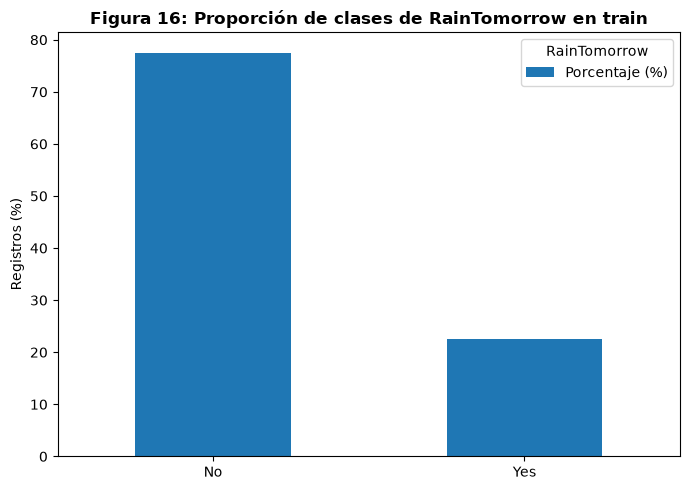

Train: la clase Yes representa 22.45% de los casos; la clase mayoritaria aparece 3.45 veces más que la minoritaria.


In [34]:
clases_objetivo = ["No", "Yes"]
reporte_balance = []
for nombre, objetivo in [("Train", y_train)]:
    clases_inesperadas = set(objetivo.dropna().unique()) - set(clases_objetivo)
    if clases_inesperadas:
        raise ValueError(f"Clases inesperadas en {nombre}: {clases_inesperadas}")
    conteos = objetivo.value_counts().reindex(clases_objetivo, fill_value=0)
    proporciones = objetivo.value_counts(normalize=True).reindex(clases_objetivo, fill_value=0) * 100
    minoritaria = conteos.min()
    relacion_desbalance = conteos.max() / minoritaria if minoritaria else np.nan
    for clase in clases_objetivo:
        reporte_balance.append({
            "Conjunto": nombre,
            "Clase": clase,
            "Cantidad": int(conteos[clase]),
            "Porcentaje (%)": proporciones[clase],
            "Relación mayoritaria/minoritaria": relacion_desbalance,
        })

reporte_balance = pd.DataFrame(reporte_balance)
display(reporte_balance.round(2))

proporciones_grafico = reporte_balance.set_index("Clase")["Porcentaje (%)"].reindex(clases_objetivo)
ax = proporciones_grafico.plot(kind="bar", figsize=(7, 5), rot=0)
ax.set_title(f"Figura {N_FIG}: Proporción de clases de RainTomorrow en train", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Registros (%)")
ax.legend(title="RainTomorrow")
plt.tight_layout()
plt.show()
N_FIG += 1

yes_train = reporte_balance.query("Conjunto == 'Train' and Clase == 'Yes'")["Porcentaje (%)"].iloc[0]
ratio_train = reporte_balance.query("Conjunto == 'Train'")["Relación mayoritaria/minoritaria"].iloc[0]
print(
    f"Train: la clase Yes representa {yes_train:.2f}% de los casos; "
    f"la clase mayoritaria aparece {ratio_train:.2f} veces más que la minoritaria."
)


La salida de balance final no cambió respecto a la realizada en secciones anteriores, contiene 88.168 casos No y 25.524 Yes: 77,55 % frente a 22,45 %, con una relación de 3,45 a 1. Se conserva esta distribución sin sobremuestrear ni submuestrear, para no modificar artificialmente las proporciones observadas y como dijimos anteoriormente ajustaremos el umbral de decisión.

# 9. Codificación de variables cualitativas

Reemplazamos Location por coordenadas geográficas aproximadas de cada localidad (no necesariamente la posición exacta de cada estación meteorológica), en grados decimales. A partir de Date creamos seno y coseno del mes para representar la continuidad entre diciembre y enero y la estacionalidad durante el año. Las tres direcciones del viento se convierten a ángulos de brújula y luego a seno y coseno, conservando su naturaleza cíclica. RainToday se codifica como 0 (No) y 1 (Yes). Aplicamos las mismas reglas a train y test y quitamos las columnas originales que ya quedaron representadas numéricamente.

In [35]:
direcciones_viento = ["WindGustDir", "WindDir9am", "WindDir3pm"]
angulos_viento = {
    direccion: angulo
    for direccion, angulo in zip(
        ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
         "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"],
        np.arange(0, 360, 22.5),
    )
}

def codificar_predictores(datos):
    codificados = datos.copy()
    codificados[cols_cloud] = codificados[cols_cloud].astype("int8")
    localidades_desconocidas = set(codificados["Location"].dropna().unique()) - set(coordenadas_localidades)
    if localidades_desconocidas:
        raise ValueError(f"Faltan coordenadas para estas localidades: {sorted(localidades_desconocidas)}")
    if codificados["Location"].isna().any():
        raise ValueError("Hay localidades nulas antes de asignar coordenadas.")

    coordenadas = codificados["Location"].map(coordenadas_localidades)
    codificados["Latitud"] = coordenadas.map(lambda valor: valor[0])
    codificados["Longitud"] = coordenadas.map(lambda valor: valor[1])

    mes = codificados["Date"].dt.month
    codificados["Mes_sin"] = np.sin(2 * np.pi * (mes - 1) / 12)
    codificados["Mes_cos"] = np.cos(2 * np.pi * (mes - 1) / 12)

    for columna in direcciones_viento:
        angulos = codificados[columna].map(angulos_viento)
        if angulos.isna().any():
            valores_invalidos = codificados.loc[angulos.isna(), columna].dropna().unique().tolist()
            if valores_invalidos or codificados[columna].isna().any():
                raise ValueError(f"Valores de dirección no reconocidos en {columna}: {valores_invalidos}")
        radianes = np.deg2rad(angulos)
        codificados[f"{columna}_sin"] = np.sin(radianes)
        codificados[f"{columna}_cos"] = np.cos(radianes)

    valores_rain_today = set(codificados["RainToday"].dropna().unique())
    if not valores_rain_today.issubset({"No", "Yes"}) or codificados["RainToday"].isna().any():
        raise ValueError(f"Valores no esperados en RainToday: {sorted(valores_rain_today)}")
    codificados["RainToday"] = codificados["RainToday"].map({"No": 0, "Yes": 1}).astype("int8")

    columnas_originales = ["Date", "Location", *direcciones_viento]
    codificados = codificados.drop(columns=columnas_originales)
    if codificados.isna().any().any():
        raise ValueError("La codificación generó o dejó valores nulos en los predictores.")
    columnas_no_numericas = codificados.select_dtypes(exclude=[np.number]).columns.tolist()
    if columnas_no_numericas:
        raise TypeError(f"Quedaron columnas no numéricas tras codificar: {columnas_no_numericas}")
    return codificados

X_train = codificar_predictores(X_train)
X_test = codificar_predictores(X_test)
if X_train.columns.tolist() != X_test.columns.tolist():
    raise AssertionError("Train y test no tienen las mismas columnas después de codificar.")

display(pd.DataFrame({
    "Variable codificada": X_train.columns,
    "Tipo": X_train.dtypes.astype(str).values,
}).reset_index(drop=True))
print(f"Dimensiones codificadas: train {X_train.shape}; test {X_test.shape}.")

,Variable codificada,Tipo
0,MinTemp,float64
1,MaxTemp,float64
2,Rainfall,float64
3,Evaporation,float64
4,Sunshine,float64
5,WindGustSpeed,float64
6,WindSpeed9am,float64
7,WindSpeed3pm,float64
8,Humidity9am,float64
9,Humidity3pm,float64


Dimensiones codificadas: train (113692, 24); test (28452, 24).


# 10. Transformación logarítmica

Aplicamos log1p(x) = log(1 + x) a Rainfall y Evaporation, variables no negativas con asimetría positiva marcada. Esta transformación admite ceros y comprime la cola derecha sin eliminar observaciones de modo que unos pocos valores extremos pesen menos en relación con los valores habituales. Esto puede ayudar a que la regresión logística modele mejor la relación entre estos predictores y la probabilidad de lluvia. El primer gráfico compara cada variable consigo misma en su escala original y después de log1p. Se conservan las versiones codificada y transformada; log1p se aplica por separado a train y test, sin ajustar parámetros a partir del conjunto de test.

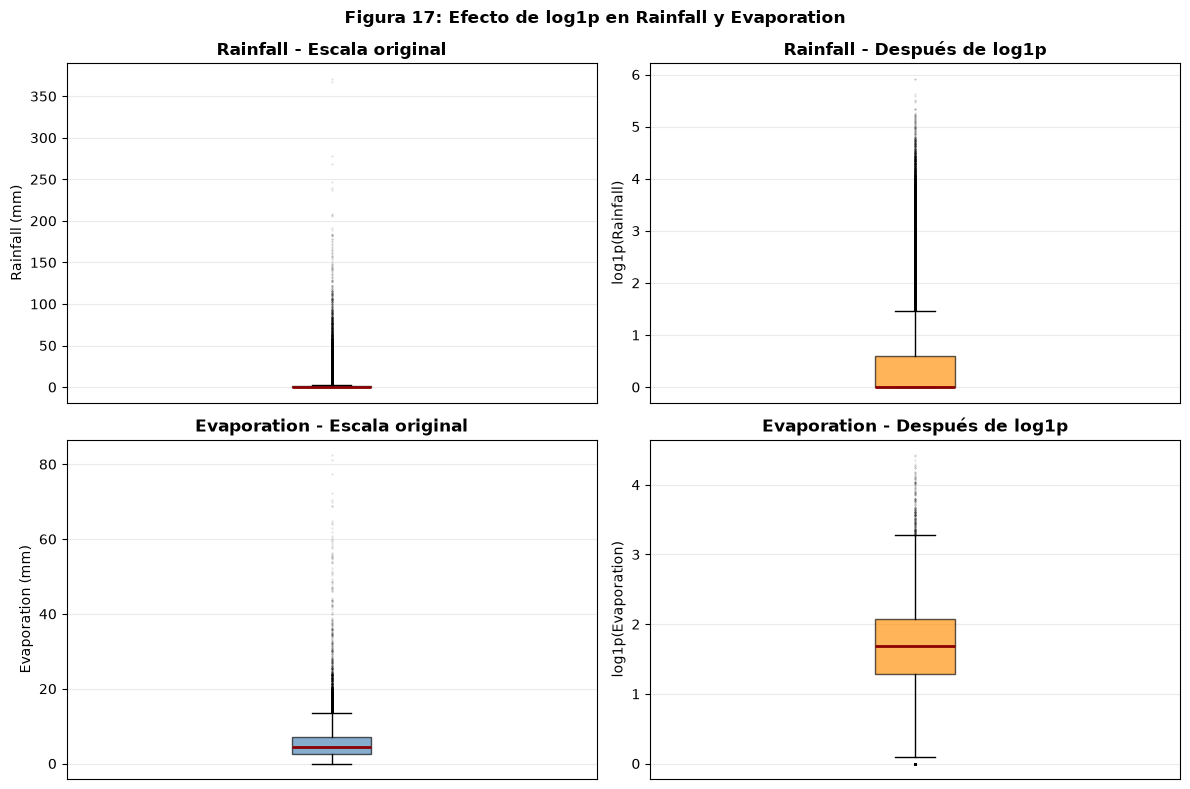

,Variable,Etapa,Mínimo,Q1,Mediana,Q3,Máximo
0,Rainfall,Escala original,0.0,0.000,0.000,0.800,371.000
1,Rainfall,Después de log1p,0.0,0.000,0.000,0.588,5.919
2,Evaporation,Escala original,0.0,2.600,4.400,7.000,82.400
3,Evaporation,Después de log1p,0.0,1.281,1.686,2.079,4.424


Transformación log1p aplicada a: ['Rainfall', 'Evaporation'].
Versiones conservadas: codificadas (113692, 24)/(28452, 24); con log1p (113692, 24)/(28452, 24).


In [36]:
X_train_codificado = X_train.copy()
X_test_codificado = X_test.copy()
if X_train_codificado.columns.tolist() != X_test_codificado.columns.tolist():
    raise AssertionError("Train y test deben tener las mismas columnas antes de escalar.")
if X_train_codificado.isna().any().any() or X_test_codificado.isna().any().any():
    raise ValueError("No se puede escalar: hay valores nulos en train o test.")
if not all(pd.api.types.is_numeric_dtype(tipo) for tipo in X_train_codificado.dtypes):
    raise TypeError("RobustScaler requiere que todas las variables estén codificadas numéricamente.")

columnas_log = ["Rainfall", "Evaporation"]
columnas_faltantes_log = set(columnas_log) - set(X_train_codificado.columns)
if columnas_faltantes_log:
    raise KeyError(f"No se encontraron las variables para transformar: {sorted(columnas_faltantes_log)}")
for conjunto_nombre, conjunto in [("train", X_train_codificado), ("test", X_test_codificado)]:
    if (conjunto[columnas_log] < 0).any().any():
        raise ValueError(f"log1p requiere valores no negativos en Rainfall y Evaporation ({conjunto_nombre}).")

X_train_log = X_train_codificado.copy()
X_test_log = X_test_codificado.copy()
for columna in columnas_log:
    X_train_log[columna] = np.log1p(X_train_codificado[columna])
    X_test_log[columna] = np.log1p(X_test_codificado[columna])

fig, axes = plt.subplots(len(columnas_log), 2, figsize=(12, 8))
for fila, columna in enumerate(columnas_log):
    for ax, datos, etapa, color in [
        (axes[fila, 0], X_train_codificado, "Escala original", "steelblue"),
        (axes[fila, 1], X_train_log, "Después de log1p", "darkorange"),
    ]:
        valores = datos[columna].dropna().to_numpy()
        ax.boxplot(
            valores,
            orientation="vertical",
            showfliers=True,
            flierprops={"marker": ".", "markersize": 1, "alpha": 0.15},
            patch_artist=True,
            boxprops={"facecolor": color, "alpha": 0.65},
            medianprops={"color": "darkred", "linewidth": 2},
        )
        ax.set_title(f"{columna} - {etapa}", fontweight="bold")
        ax.set_ylabel(f"{columna} (mm)" if datos is X_train_codificado else f"log1p({columna})")
        ax.set_xticks([])
        ax.grid(axis="y", alpha=0.25)
fig.suptitle(f"Figura {N_FIG}: Efecto de log1p en Rainfall y Evaporation", fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

filas_resumen_log = []
for columna in columnas_log:
    for etapa, datos in [("Escala original", X_train_codificado), ("Después de log1p", X_train_log)]:
        valores = datos[columna].dropna()
        filas_resumen_log.append({
            "Variable": columna,
            "Etapa": etapa,
            "Mínimo": valores.min(),
            "Q1": valores.quantile(0.25),
            "Mediana": valores.median(),
            "Q3": valores.quantile(0.75),
            "Máximo": valores.max(),
        })
display(pd.DataFrame(filas_resumen_log).round(3))

print(f"Transformación log1p aplicada a: {columnas_log}.")
print(f"Versiones conservadas: codificadas {X_train_codificado.shape}/{X_test_codificado.shape}; con log1p {X_train_log.shape}/{X_test_log.shape}.")


# 11. Escalado de datos

Aplicamos RobustScaler sobre las variables hasta con las ya transformadas con log1p salvo RainToday y las variables cíclicas seno/coseno que quedan sin escalar para mantener su representación. El escalador centra con la mediana y divide por el rango intercuartílico (Q3 - Q1), se ajusta únicamente con train y luego se aplica a test. Los boxplots muestran, para cada una de las variables escaladas, la comparación antes y después de RobustScaler, incluidos Rainfall y Evaporation después de log1p. Los valores atípicos se conservan y se muestran como puntos por fuera de los bigotes pero no reduce por sí mismo la asimetría ni limita los valores extremos. La tabla resume mínimos, máximos y cuartiles de todas las variables escaladas.

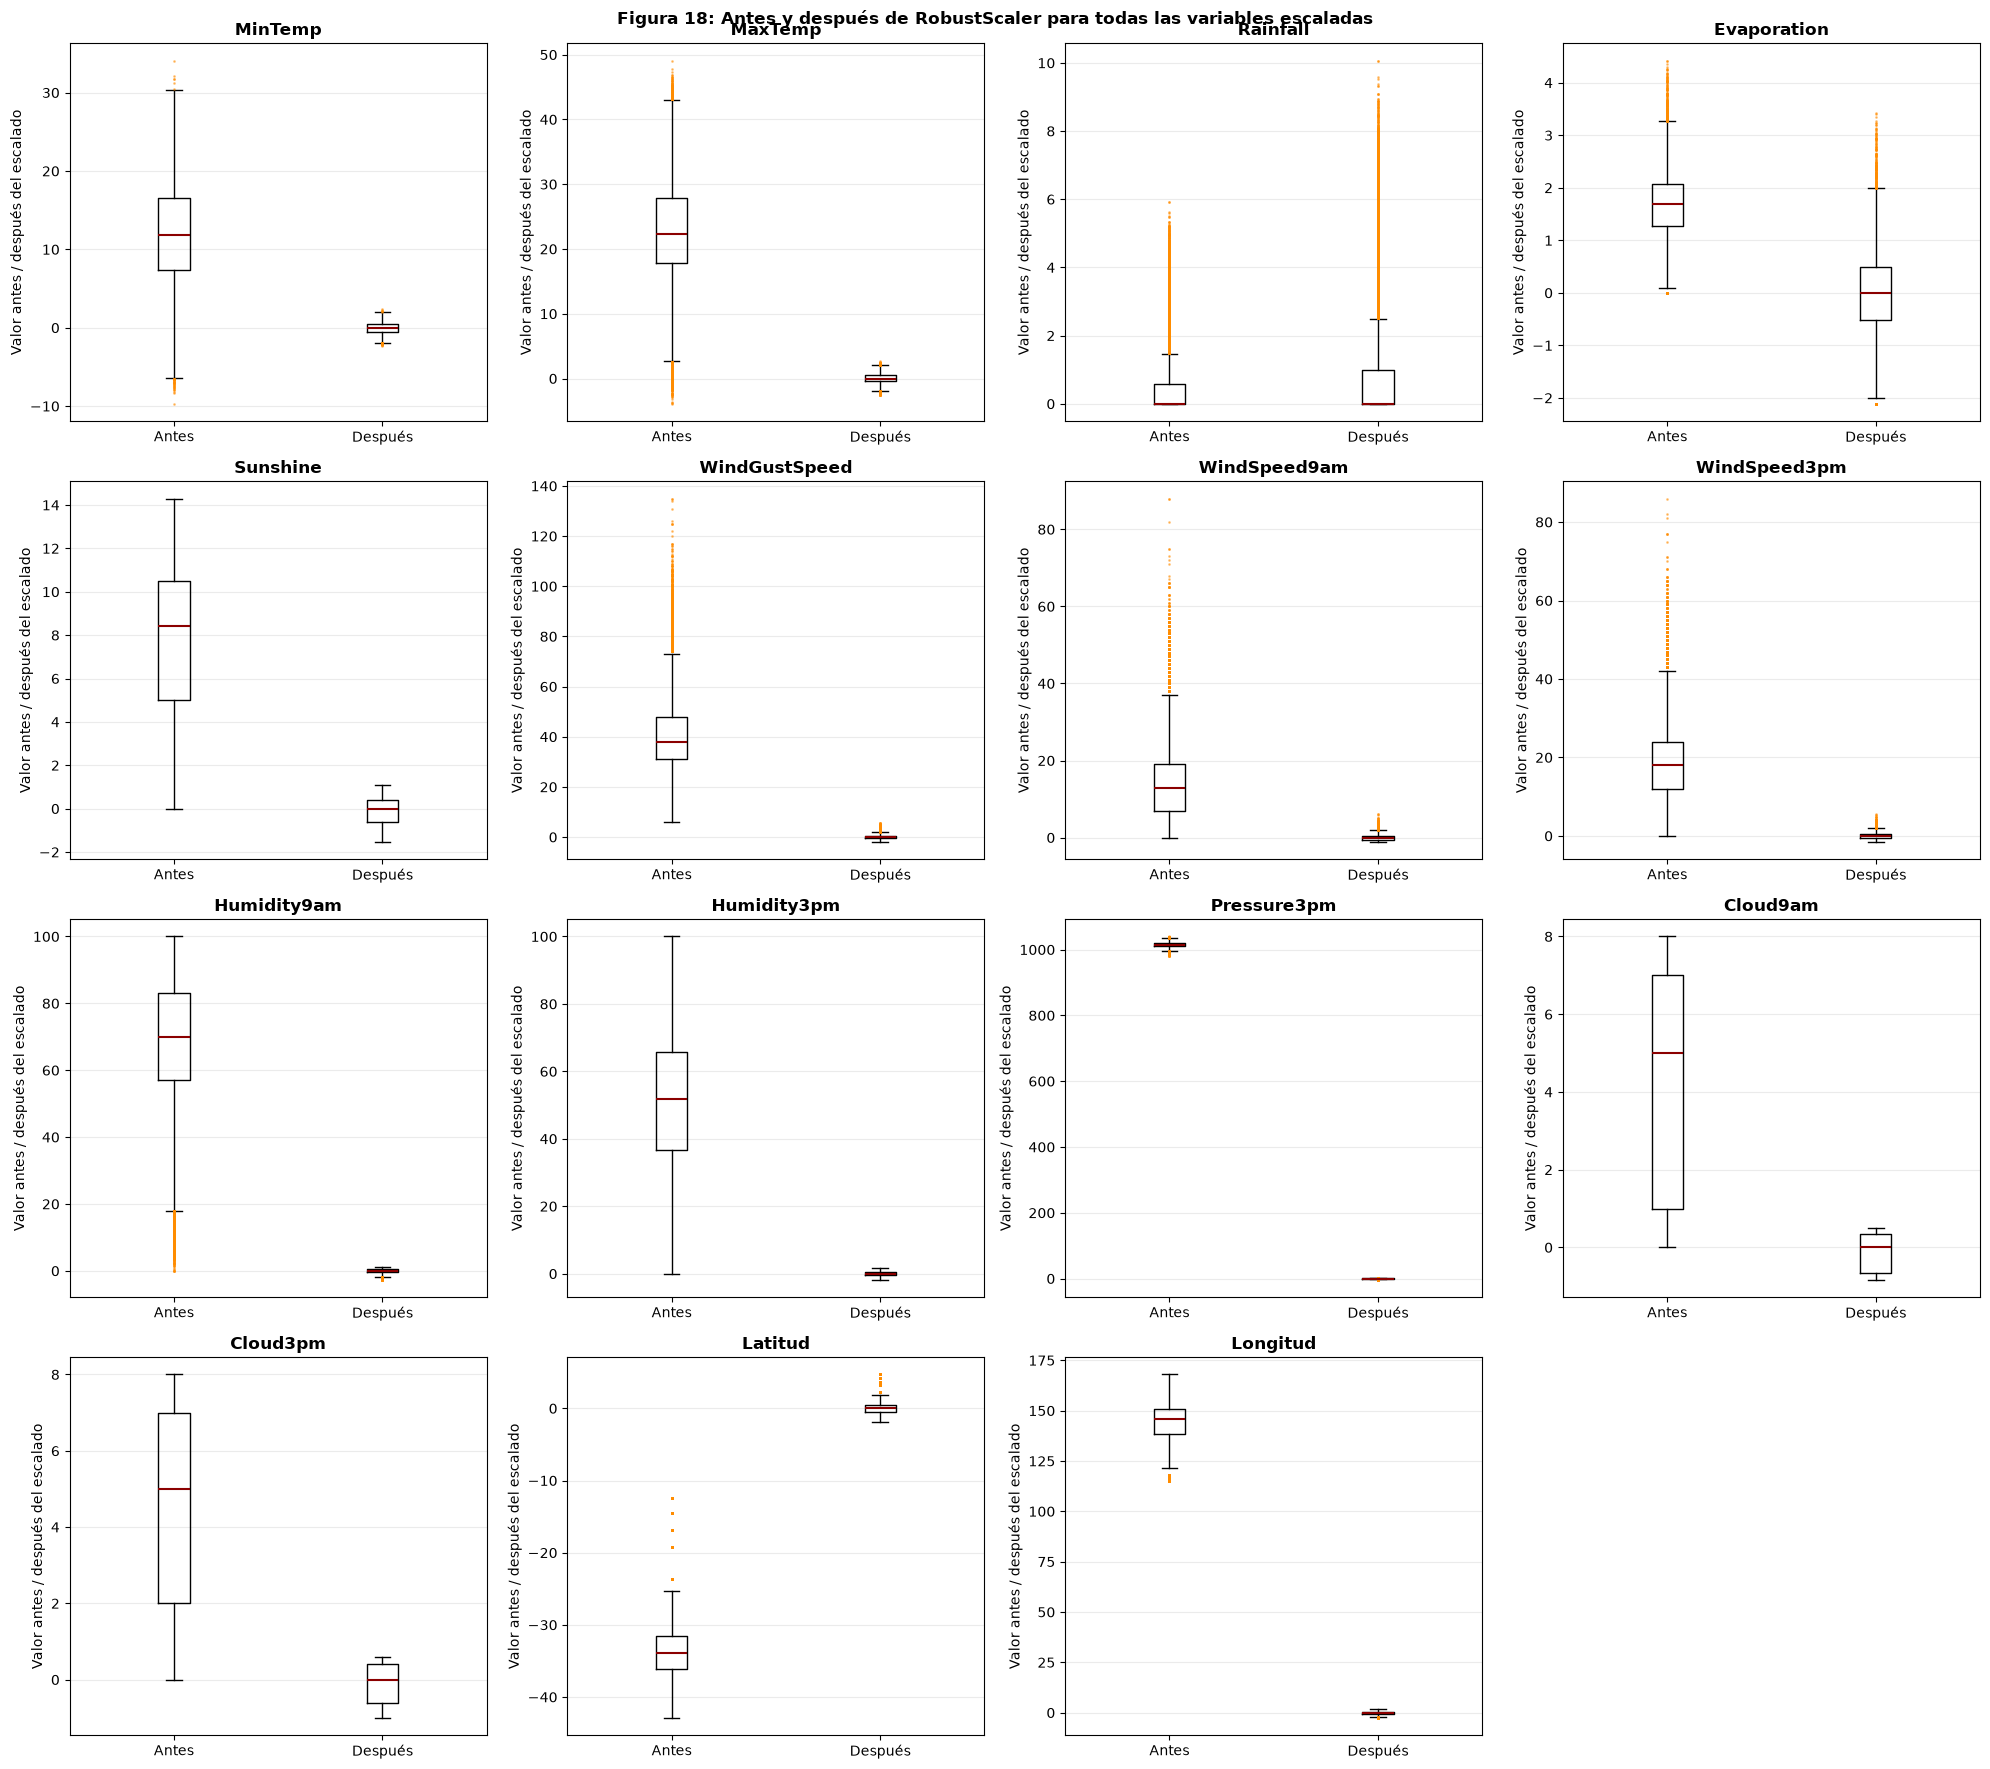

,Variable,Etapa,Mínimo,Q1,Mediana,Q3,Máximo
0,MinTemp,Después de RobustScaler,-2.337,-0.478,0.0,0.522,2.424
1,MaxTemp,Después de RobustScaler,-2.594,-0.446,0.0,0.554,2.653
2,Rainfall,Después de RobustScaler,0.000,0.000,0.0,1.000,10.070
3,Evaporation,Después de RobustScaler,-2.112,-0.508,0.0,0.492,3.428
4,Sunshine,Después de RobustScaler,-1.527,-0.618,0.0,0.382,1.073
5,WindGustSpeed,Después de RobustScaler,-1.882,-0.412,0.0,0.588,5.706
6,WindSpeed9am,Después de RobustScaler,-1.083,-0.500,0.0,0.500,6.250
7,WindSpeed3pm,Después de RobustScaler,-1.500,-0.500,0.0,0.500,5.667
8,Humidity9am,Después de RobustScaler,-2.678,-0.494,0.0,0.506,1.153
9,Humidity3pm,Después de RobustScaler,-1.802,-0.524,0.0,0.476,1.670


RobustScaler ajustado solo con train y aplicado a test. Variables escaladas: 15.
Versiones disponibles: con log1p (113692, 24)/(28452, 24); escaladas (113692, 24)/(28452, 24).


In [37]:
columnas_sin_escalar = {
    "RainToday", "Mes_sin", "Mes_cos",
    "WindGustDir_sin", "WindGustDir_cos",
    "WindDir9am_sin", "WindDir9am_cos",
    "WindDir3pm_sin", "WindDir3pm_cos",
}
columnas_escalar_robusto = [
    col for col in X_train_log.columns if col not in columnas_sin_escalar
]
escalador_robusto = RobustScaler()
X_train_robust = X_train_log.copy()
X_test_robust = X_test_log.copy()
X_train_robust[columnas_escalar_robusto] = escalador_robusto.fit_transform(
    X_train_log[columnas_escalar_robusto]
)
X_test_robust[columnas_escalar_robusto] = escalador_robusto.transform(
    X_test_log[columnas_escalar_robusto]
)

n_columnas_grafico = 4
n_filas_grafico = (len(columnas_escalar_robusto) + n_columnas_grafico - 1) // n_columnas_grafico
fig, axes = plt.subplots(
    n_filas_grafico,
    n_columnas_grafico,
    figsize=(20, 4.5 * n_filas_grafico),
    squeeze=False,
)
for indice, columna in enumerate(columnas_escalar_robusto):
    fila, columna_grafico = divmod(indice, n_columnas_grafico)
    ax = axes[fila, columna_grafico]
    valores_antes = X_train_log[columna].dropna().to_numpy()
    valores_despues = X_train_robust[columna].dropna().to_numpy()
    ax.boxplot(
        [valores_antes, valores_despues],
        tick_labels=["Antes", "Después"],
        showfliers=True,
        flierprops={"marker": ".", "markersize": 2, "markerfacecolor": "darkorange", "markeredgecolor": "darkorange", "alpha": 0.45},
        medianprops={"color": "darkred", "linewidth": 1.5},
    )
    ax.set_title(columna, fontweight="bold")
    ax.set_ylabel("Valor antes / después del escalado")
    ax.grid(axis="y", alpha=0.25)

for indice_sin_grafico in range(len(columnas_escalar_robusto), n_filas_grafico * n_columnas_grafico):
    fila, columna_grafico = divmod(indice_sin_grafico, n_columnas_grafico)
    axes[fila, columna_grafico].set_visible(False)
fig.suptitle(
    f"Figura {N_FIG}: Antes y después de RobustScaler para todas las variables escaladas",
    fontweight="bold",
)
N_FIG += 1
plt.tight_layout()
plt.show()

filas_resumen = []
for columna in columnas_escalar_robusto:
    for etapa, datos in [("Después de RobustScaler", X_train_robust)]:
        valores = datos[columna].dropna()
        filas_resumen.append({
            "Variable": columna,
            "Etapa": etapa,
            "Mínimo": valores.min(),
            "Q1": valores.quantile(0.25),
            "Mediana": valores.median(),
            "Q3": valores.quantile(0.75),
            "Máximo": valores.max(),
        })
display(pd.DataFrame(filas_resumen).round(3))
print(f"RobustScaler ajustado solo con train y aplicado a test. Variables escaladas: {len(columnas_escalar_robusto)}.")
print(f"Versiones disponibles: con log1p {X_train_log.shape}/{X_test_log.shape}; escaladas {X_train_robust.shape}/{X_test_robust.shape}.")


# 12. Regresión logística


El objetivo positivo será RainTomorrow = Yes. Una vez reservado el conjunto de test, dividimos train cronológicamente en tres tramos con funciones distintas. El primero, que contiene aproximadamente el 70 % de las observaciones, se utiliza para ajustar los parámetros del modelo. El segundo, con aproximadamente el 15 %, se emplea para seleccionar el umbral de decisión que maximiza el recall sujeto a la precisión mínima definida. El último 15 % se reserva como validación interna para observar cómo se comporta el modelo en fechas posteriores que no participaron en el ajuste ni en la elección del umbral.

Esta separación respeta el orden temporal: en cada etapa se usan datos anteriores para tomar decisiones y datos posteriores para evaluarlas, sin mezclar observaciones de distintas fechas al azar. Así se evita que información del futuro influya en el entrenamiento y se obtiene una evaluación más realista para el objetivo de predecir días posteriores.

Una vez seleccionados el umbral y las decisiones del modelo, la regresión logística se vuelve a ajustar con todo el conjunto de entrenamiento. El conjunto de test, reservado desde el inicio y compuesto por fechas posteriores, se utiliza únicamente para la evaluación final y la comparación con el modelo base.

## 12.1. Ajuste temporal del modelo y selección del umbral

La logística estima una probabilidad de lluvia para mañana y usa regularización L2 por defecto. Configuramos class_weight="balanced" en el mismo modelo para que los errores de la clase minoritaria Yes tengan mayor peso durante el ajuste, de tal forma que no sobremuestreamos ni submuestreamos observaciones. Como esta ponderación cambia el ajuste y la interpretación de las probabilidades, seleccionamos el umbral empíricamente en un tramo cronológico separado. La validación interna posterior permite comprobar el comportamiento sin usar ese tramo para elegirlo y el test permanece reservado.

In [38]:
# Comprobaciones de alineación antes del modelado.
if not X_train_log.index.is_unique or not X_test_log.index.is_unique:
    raise AssertionError("Los índices de train y test deben ser únicos.")
if not X_train_log.index.equals(y_train.loc[X_train_log.index].index):
    raise AssertionError("X_train_log e y_train no están alineados.")
if not X_test_log.index.equals(y_test.loc[X_test_log.index].index):
    raise AssertionError("X_test_log e y_test no están alineados.")

mapa_clases = {"No": 0, "Yes": 1}
y_train_bin = y_train.loc[X_train_log.index].map(mapa_clases)
y_test_bin = y_test.loc[X_test_log.index].map(mapa_clases)
if y_train_bin.isna().any() or y_test_bin.isna().any():
    raise ValueError("El objetivo contiene clases nulas o distintas de No/Yes.")

dates_train_modelo = pd.to_datetime(
    train.loc[X_train_log.index, "Date"], errors="raise"
)
if dates_train_modelo.isna().any():
    raise ValueError("Hay fechas nulas en train; no se puede hacer la validación temporal.")

def corte_temporal_por_proporcion(fechas, proporcion):
    conteos = fechas.value_counts().sort_index()
    objetivo = proporcion * len(fechas)
    return (conteos.cumsum() - objetivo).abs().idxmin()

corte_ajuste = corte_temporal_por_proporcion(dates_train_modelo, 0.70)
corte_seleccion = corte_temporal_por_proporcion(dates_train_modelo, 0.85)
mascara_ajuste = dates_train_modelo <= corte_ajuste
mascara_seleccion = (dates_train_modelo > corte_ajuste) & (dates_train_modelo <= corte_seleccion)
mascara_validacion = dates_train_modelo > corte_seleccion

if not mascara_ajuste.any() or not mascara_seleccion.any() or not mascara_validacion.any():
    raise ValueError("La partición temporal produjo un tramo vacío.")

X_ajuste = X_train_log.loc[mascara_ajuste]
y_ajuste = y_train_bin.loc[X_ajuste.index]
X_seleccion = X_train_log.loc[mascara_seleccion]
y_seleccion = y_train_bin.loc[X_seleccion.index]
X_validacion = X_train_log.loc[mascara_validacion]
y_validacion = y_train_bin.loc[X_validacion.index]

for nombre, objetivo in [("ajuste", y_ajuste), ("selección", y_seleccion), ("validación", y_validacion)]:
    if objetivo.nunique() != 2:
        raise ValueError(f"El tramo de {nombre} no contiene ambas clases; revise los cortes temporales.")

columnas_no_escalar_modelo = {
    "RainToday", "Mes_sin", "Mes_cos",
    "WindGustDir_sin", "WindGustDir_cos",
    "WindDir9am_sin", "WindDir9am_cos",
    "WindDir3pm_sin", "WindDir3pm_cos",
}
columnas_escalar_modelo = [
    columna for columna in X_train_log.columns
    if columna not in columnas_no_escalar_modelo
]
if not columnas_escalar_modelo:
    raise ValueError("No se encontraron variables para el escalado robusto.")

def ajustar_escalador_y_transformar(escalador, datos_ajuste, datos_aplicar):
    ajuste_escalado = datos_ajuste.copy()
    aplicar_escalado = datos_aplicar.copy()
    ajuste_escalado[columnas_escalar_modelo] = escalador.fit_transform(
        datos_ajuste[columnas_escalar_modelo]
    )
    aplicar_escalado[columnas_escalar_modelo] = escalador.transform(
        datos_aplicar[columnas_escalar_modelo]
    )
    return ajuste_escalado, aplicar_escalado

escalador_validacion = RobustScaler()
X_ajuste_escalado, X_seleccion_escalado = ajustar_escalador_y_transformar(
    escalador_validacion, X_ajuste, X_seleccion
)
_, X_validacion_escalado = ajustar_escalador_y_transformar(
    escalador_validacion, X_ajuste, X_validacion
)

modelo_validacion = LogisticRegression(max_iter=2000, solver="lbfgs", class_weight="balanced", random_state=RANDOM_STATE)
modelo_validacion.fit(X_ajuste_escalado, y_ajuste)
prob_ajuste = modelo_validacion.predict_proba(X_ajuste_escalado)[:, 1]
prob_seleccion = modelo_validacion.predict_proba(X_seleccion_escalado)[:, 1]
prob_validacion = modelo_validacion.predict_proba(X_validacion_escalado)[:, 1]

precision_seleccion, recall_seleccion, umbrales_seleccion = precision_recall_curve(
    y_seleccion, prob_seleccion
)
if len(umbrales_seleccion) == 0:
    raise ValueError("No se pudieron calcular umbrales para el tramo de selección.")
precision_minima = 0.50
indices_cumplen_precision = np.flatnonzero(
    precision_seleccion[:-1] >= precision_minima
)
if len(indices_cumplen_precision) == 0:
    raise ValueError(
        f"Ningún umbral alcanza la precision mínima de {precision_minima:.2f} "
        "en el tramo de selección. Revisar la restricción o el modelo."
    )
recall_candidatos = recall_seleccion[indices_cumplen_precision]
mejor_recall = recall_candidatos.max()
indices_mejor_recall = indices_cumplen_precision[
    np.isclose(recall_candidatos, mejor_recall)
]
indice_umbral = indices_mejor_recall[-1]  # En empates se elige el umbral m\u00e1s alto.
umbral_logistico = float(umbrales_seleccion[indice_umbral])
precision_umbral_seleccion = float(precision_seleccion[indice_umbral])
recall_umbral_seleccion = float(recall_seleccion[indice_umbral])

# Reajustamos el escalador y el modelo con todo el train; el test sigue sin intervenir.
escalador_final = RobustScaler()
X_train_final = X_train_log.copy()
X_test_final = X_test_log.copy()
X_train_final[columnas_escalar_modelo] = escalador_final.fit_transform(
    X_train_log[columnas_escalar_modelo]
)
X_test_final[columnas_escalar_modelo] = escalador_final.transform(
    X_test_log[columnas_escalar_modelo]
)
modelo_logistico = LogisticRegression(max_iter=2000, solver="lbfgs", class_weight="balanced", random_state=RANDOM_STATE)
modelo_logistico.fit(X_train_final, y_train_bin)
prob_test_logistica = modelo_logistico.predict_proba(X_test_final)[:, 1]

print(f"Tramo de ajuste: hasta {corte_ajuste.date()} ({len(X_ajuste):,} filas).")
print(f"Tramo de selección del umbral: posterior a {corte_ajuste.date()} y hasta {corte_seleccion.date()} ({len(X_seleccion):,} filas).")
print(f"Validación interna: posterior a {corte_seleccion.date()} ({len(X_validacion):,} filas).")
print(f"Precision mínima exigida en selección: {precision_minima:.2f}.")
print(f"Umbral elegido por máximo recall sujeto a precision mínima: {umbral_logistico:.4f}.")
print(f"En selección: precision={precision_umbral_seleccion:.4f}; recall={recall_umbral_seleccion:.4f}.")
print(f"Iteraciones de la logística de validación: {modelo_validacion.n_iter_[0]}.")
print(f"Iteraciones de la logística final: {modelo_logistico.n_iter_[0]}.")


Tramo de ajuste: hasta 2013-11-20 (79,605 filas).
Tramo de selección del umbral: posterior a 2013-11-20 y hasta 2014-11-12 (17,047 filas).
Validación interna: posterior a 2014-11-12 (17,040 filas).
Precision mínima exigida en selección: 0.50.
Umbral elegido por máximo recall sujeto a precision mínima: 0.4728.
En selección: precision=0.5002; recall=0.7802.
Iteraciones de la logística de validación: 25.
Iteraciones de la logística final: 24.


## 12.2. Elección del umbral

Predecimos Yes cuando la probabilidad estimada alcanza el umbral. Como el objetivo es reducir los falsos negativos, elegimos en el tramo de selección el umbral que obtiene el mayor recall posible sujeto a una precision mínima de 0,50. Esto exige que al menos la mitad de los días pronosticados como lluviosos sean lluviosos en ese tramo, evitando la solución trivial de predecir lluvia siempre. Si ningún umbral cumple la restricción. El valor 0,50 es un criterio inicial acordado.

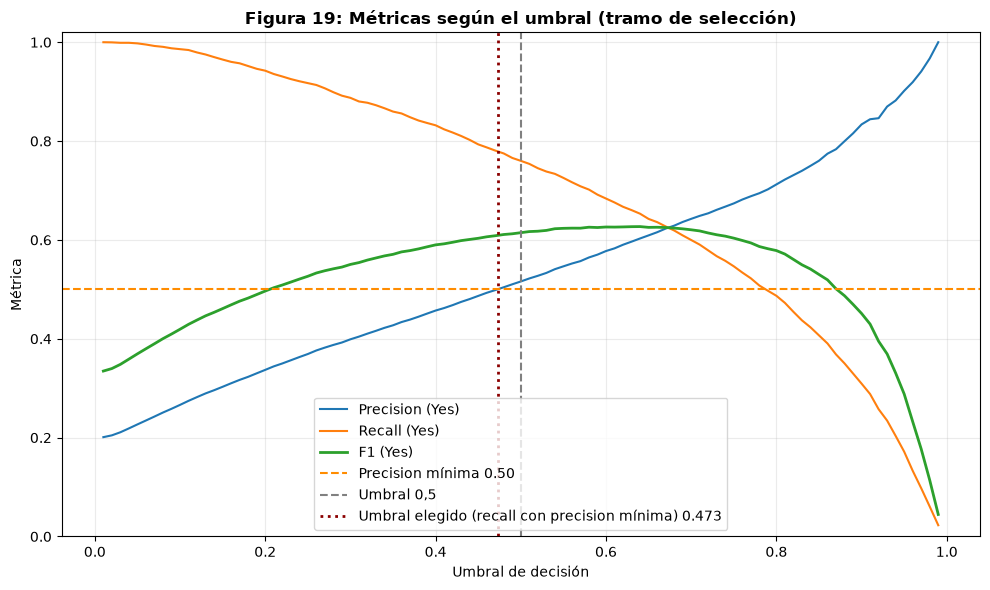

In [39]:
umbrales_grafico = np.linspace(0.01, 0.99, 99)
precision_grafico = []
recall_grafico = []
f1_grafico = []
for umbral in umbrales_grafico:
    prediccion = (prob_seleccion >= umbral).astype(int)
    precision_grafico.append(precision_score(y_seleccion, prediccion, zero_division=0))
    recall_grafico.append(recall_score(y_seleccion, prediccion, zero_division=0))
    f1_grafico.append(f1_score(y_seleccion, prediccion, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(umbrales_grafico, precision_grafico, label="Precision (Yes)")
ax.plot(umbrales_grafico, recall_grafico, label="Recall (Yes)")
ax.plot(umbrales_grafico, f1_grafico, label="F1 (Yes)", linewidth=2)
ax.axhline(precision_minima, color="darkorange", linestyle="--", label=f"Precision mínima {precision_minima:.2f}")
ax.axvline(0.5, color="gray", linestyle="--", label="Umbral 0,5")
ax.axvline(umbral_logistico, color="darkred", linestyle=":", linewidth=2,
           label=f"Umbral elegido (recall con precision mínima) {umbral_logistico:.3f}")
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend()
ax.set_title(f"Figura {N_FIG}: Métricas según el umbral (tramo de selección)", fontweight="bold")
plt.tight_layout()
plt.show()
N_FIG += 1


## 12.3. Métricas y matriz de confusión de la regresión logística

Consideramos Yes como clase positiva. Un falso positivo (FP) es un día pronosticado lluvioso cuando RainTomorrow fue No (falsa alarma). Un falso negativo (FN) es un día pronosticado sin lluvia cuando RainTomorrow fue Yes (lluvia no anticipada). La matriz de confusión muestra sus cantidades. Reportamos precision y recall de Yes, F1, especificidad, balanced accuracy, ROC-AUC y Average Precision, además de accuracy. El desbalance de clases hace que accuracy aislada pueda ser engañosa. La tabla compara el umbral 0,5 con el elegido para maximizar recall sujeto a precision mínima de 0,50, la evaluación final usa el test temporal, que no participó en esa decisión.

In [40]:
def calcular_metricas_clasificacion(y_real, scores, umbral):
    y_real_array = np.asarray(y_real, dtype=int)
    scores_array = np.asarray(scores, dtype=float)
    y_predicho = (scores_array >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real_array, y_predicho, labels=[0, 1]).ravel()
    return {
        "Umbral": float(umbral),
        "Accuracy": accuracy_score(y_real_array, y_predicho),
        "Precision (Yes)": precision_score(y_real_array, y_predicho, zero_division=0),
        "Recall (Yes)": recall_score(y_real_array, y_predicho, zero_division=0),
        "F1 (Yes)": f1_score(y_real_array, y_predicho, zero_division=0),
        "Especificidad (No)": tn / (tn + fp) if (tn + fp) else np.nan,
        "Balanced accuracy": balanced_accuracy_score(y_real_array, y_predicho),
        "ROC-AUC": roc_auc_score(y_real_array, scores_array),
        "Average Precision": average_precision_score(y_real_array, scores_array),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

metricas_logistica_05 = calcular_metricas_clasificacion(
    y_test_bin, prob_test_logistica, 0.5
)
metricas_logistica_ajustada = calcular_metricas_clasificacion(
    y_test_bin, prob_test_logistica, umbral_logistico
)
tabla_metricas_logistica = pd.DataFrame([
    {"Modelo": "Regresión logística (umbral 0,5)", **metricas_logistica_05},
    {"Modelo": f"Regresión logística (recall, precision >= {precision_minima:.2f}; umbral={umbral_logistico:.3f})", **metricas_logistica_ajustada},
]).set_index("Modelo")
display(tabla_metricas_logistica.round(4))


,Umbral,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),Especificidad (No),Balanced accuracy,ROC-AUC,Average Precision,TN,FP,FN,TP
Modelo,,,,,,,,,,,,,
"Regresión logística (umbral 0,5)",0.5000,0.7868,0.5149,0.7668,0.6161,0.7925,0.7797,0.8623,0.6827,17519,4586,1480,4867
"Regresión logística (recall, precision >= 0.50; umbral=0.473)",0.4728,0.7752,0.4976,0.7867,0.6096,0.7720,0.7793,0.8623,0.6827,17064,5041,1354,4993


## 12.4. Diagnóstico del fitting

Para valorar el ajuste comparamos el desempeño en el tramo usado para estimar los coeficientes con el de la validación interna, manteniendo el umbral seleccionado. El resultado de entrenamiento es una medida sobre los mismos datos usados para ajustar y suele ser optimista; la validación interna aporta evidencia más útil de generalización. Una diferencia grande entre ambos puede indicar sobreajuste; resultados bajos en ambos pueden indicar subajuste o falta de señal. No concluimos que el fitting sea bueno solo por accuracy: observamos también recall, F1, ROC-AUC y Average Precision. La confirmación final corresponde al test temporal, que permanece separado.

In [41]:
tabla_fitting = pd.DataFrame([
    {"Tramo": "Ajuste (in-sample)", **calcular_metricas_clasificacion(y_ajuste, prob_ajuste, umbral_logistico)},
    {"Tramo": "Validación interna", **calcular_metricas_clasificacion(y_validacion, prob_validacion, umbral_logistico)},
]).set_index("Tramo")
display(tabla_fitting.round(4))


,Umbral,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),Especificidad (No),Balanced accuracy,ROC-AUC,Average Precision,TN,FP,FN,TP
Tramo,,,,,,,,,,,,,
Ajuste (in-sample),0.4728,0.7877,0.5260,0.8035,0.6358,0.783,0.7932,0.8779,0.7181,47959,13289,3608,14749
Validación interna,0.4728,0.7957,0.5242,0.7624,0.6213,0.805,0.7837,0.8684,0.6896,10702,2592,890,2856


# 13. Modelo base y comparación

Como modelo base para comparar usamos el que realiza la siguiente comprobación: si hoy llovió (RainToday = Yes), predecimos que mañana lloverá; si hoy no llovió, predecimos que mañana no lloverá. Es un baseline razonable porque usa una señal disponible y fácil de explicar.

## 13.1. Evaluación de la regla RainToday

La regla produce una predicción binaria fija. Para la curva ROC usamos ese indicador binario como score; por eso la curva del baseline tendrá pocos puntos y representa únicamente el orden que induce la regla, no probabilidades calibradas. El baseline no necesita elegir un umbral. Sus falsos positivos y falsos negativos se interpretan igual que los de la regresión logística.

In [42]:
if not X_test.index.equals(y_test.index):
    raise AssertionError("X_test e y_test no están alineados para evaluar el baseline.")
if "RainToday" not in X_test.columns:
    raise KeyError("No se encontró RainToday para construir el modelo base.")

scores_baseline = X_test.loc[y_test.index, "RainToday"].astype(int).to_numpy()
if not set(np.unique(scores_baseline)).issubset({0, 1}):
    raise ValueError("RainToday debe estar codificada como 0/1 para la regla base.")
predicciones_baseline = scores_baseline.copy()
metricas_baseline = calcular_metricas_clasificacion(y_test_bin, scores_baseline, 0.5)
tabla_baseline = pd.DataFrame([{"Modelo": "Regla RainToday", **metricas_baseline}]).set_index("Modelo")
display(tabla_baseline.round(4))


,Umbral,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),Especificidad (No),Balanced accuracy,ROC-AUC,Average Precision,TN,FP,FN,TP
Modelo,,,,,,,,,,,,,
Regla RainToday,0.5,0.754,0.4484,0.447,0.4477,0.8421,0.6445,0.6445,0.3238,18615,3490,3510,2837


## 13.2. Comparación final de métricas, matrices de confusión y curvas ROC

Comparamos en el mismo test la regresión logística balanceada con umbral 0,5, la misma regresión con umbral elegido por máximo recall sujeto a precision mínima de 0,50 y la regla base. La matriz hace visibles FP y FN para cada decisión. Las curvas ROC muestran el trade-off entre tasa de verdaderos positivos y tasa de falsos positivos, también marcan los puntos de operación. El ROC-AUC resume la ordenación, pero, dado el desbalance, se interpreta junto con Average Precision, recall, precision y los conteos de errores.

,Umbral,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),Especificidad (No),Balanced accuracy,ROC-AUC,Average Precision,TN,FP,FN,TP
Modelo,,,,,,,,,,,,,
"Regresión logística (0,5)",0.5000,0.7868,0.5149,0.7668,0.6161,0.7925,0.7797,0.8623,0.6827,17519,4586,1480,4867
"Regresión logística (recall, precision >= 0.50; 0.473)",0.4728,0.7752,0.4976,0.7867,0.6096,0.7720,0.7793,0.8623,0.6827,17064,5041,1354,4993
Regla RainToday,0.5000,0.7540,0.4484,0.4470,0.4477,0.8421,0.6445,0.6445,0.3238,18615,3490,3510,2837


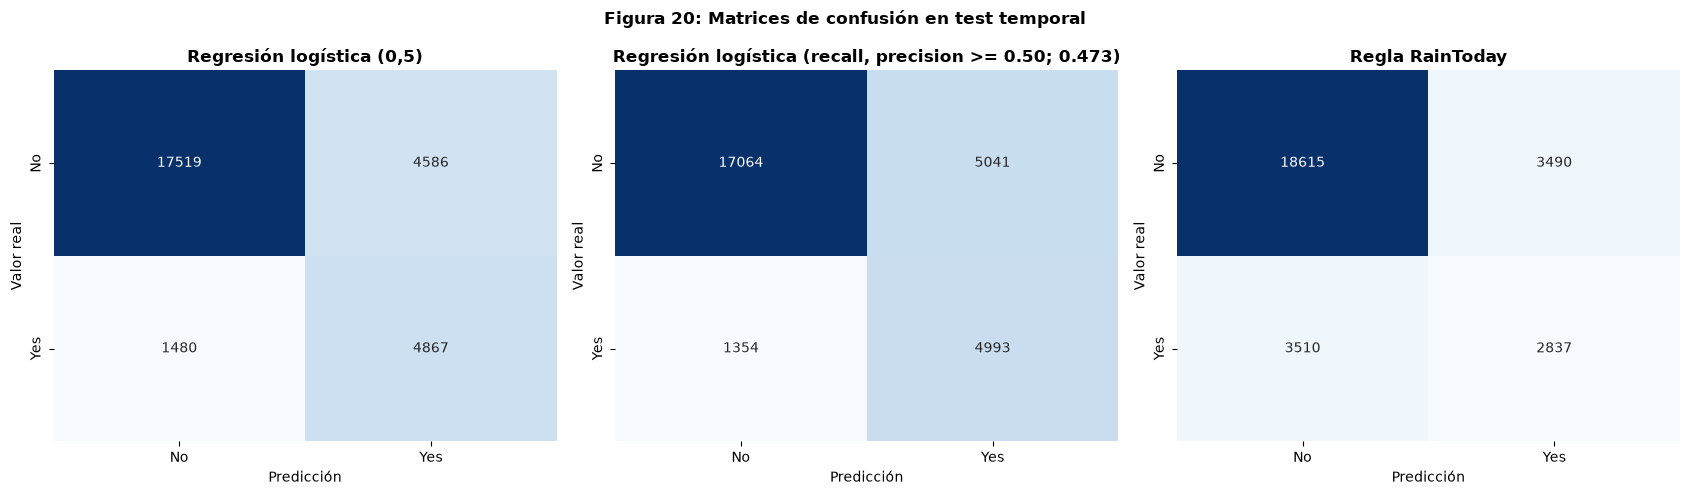

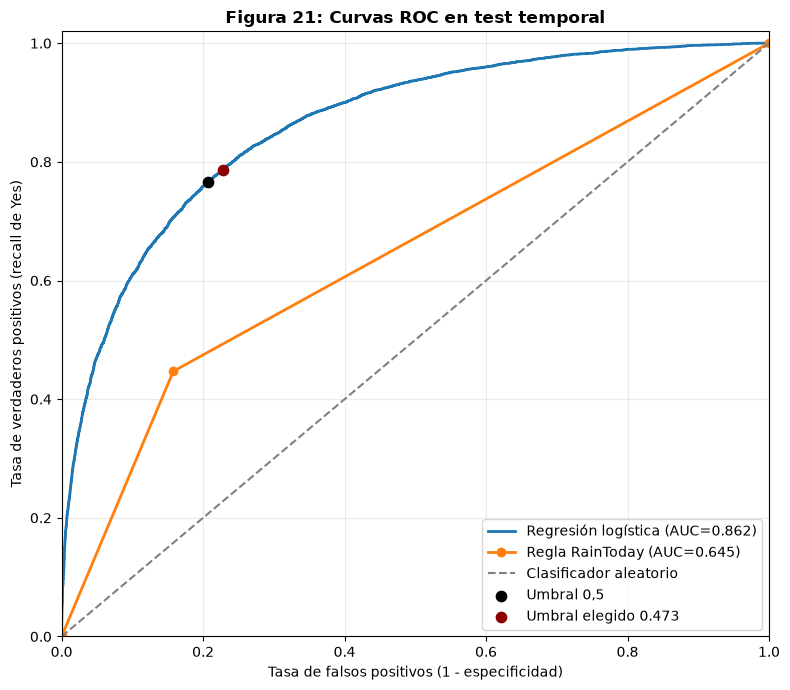

In [43]:
comparaciones_test = [
    ("Regresión logística (0,5)", prob_test_logistica, 0.5),
    (f"Regresión logística (recall, precision >= {precision_minima:.2f}; {umbral_logistico:.3f})", prob_test_logistica, umbral_logistico),
    ("Regla RainToday", scores_baseline, 0.5),
]
filas_metricas_comparacion = []
for nombre, scores, umbral in comparaciones_test:
    filas_metricas_comparacion.append({
        "Modelo": nombre,
        **calcular_metricas_clasificacion(y_test_bin, scores, umbral),
    })
tabla_comparacion_modelos = pd.DataFrame(filas_metricas_comparacion).set_index("Modelo")
display(tabla_comparacion_modelos.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (nombre, scores, umbral) in zip(axes, comparaciones_test):
    predicho = (np.asarray(scores) >= umbral).astype(int)
    matriz = confusion_matrix(y_test_bin, predicho, labels=[0, 1])
    sns.heatmap(
        matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["No", "Yes"], yticklabels=["No", "Yes"],
    )
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.set_title(nombre, fontweight="bold")
fig.suptitle(f"Figura {N_FIG}: Matrices de confusión en test temporal", fontweight="bold")
plt.tight_layout()
plt.show()
N_FIG += 1

fig, ax = plt.subplots(figsize=(8, 7))
fpr_logistica, tpr_logistica, umbrales_roc_logistica = roc_curve(y_test_bin, prob_test_logistica)
auc_logistica = roc_auc_score(y_test_bin, prob_test_logistica)
ax.plot(fpr_logistica, tpr_logistica, linewidth=2, label=f"Regresión logística (AUC={auc_logistica:.3f})")
fpr_baseline, tpr_baseline, _ = roc_curve(y_test_bin, scores_baseline)
auc_baseline = roc_auc_score(y_test_bin, scores_baseline)
ax.plot(fpr_baseline, tpr_baseline, marker="o", linewidth=2,
        label=f"Regla RainToday (AUC={auc_baseline:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")

for umbral, etiqueta, color in [(0.5, "Umbral 0,5", "black"),
                                (umbral_logistico, f"Umbral elegido {umbral_logistico:.3f}", "darkred")]:
    indice = int(np.argmin(np.abs(umbrales_roc_logistica - umbral)))
    ax.scatter(fpr_logistica[indice], tpr_logistica[indice], color=color, s=55, zorder=3, label=etiqueta)
ax.set_xlabel("Tasa de falsos positivos (1 - especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (recall de Yes)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
ax.set_title(f"Figura {N_FIG}: Curvas ROC en test temporal", fontweight="bold")
plt.tight_layout()
plt.show()
N_FIG += 1


## 13.3. Conclusión de la comparación

Como el objetivo principal es reducir los días lluviosos que el modelo deja sin detectar, comparamos especialmente el recall de Yes y los falsos negativos (FN), sin ignorar el costo en falsas alarmas. En el test temporal, la regresión logística con umbral 0,473 obtuvo recall 0,7867 y 1.354 FN; la regla base RainToday obtuvo recall 0,4470 y 3.510 FN. Por lo tanto, en este test la logística detectó una proporción mayor de días lluviosos y tuvo 2.156 FN menos (aproximadamente 61,4 % menos) que el baseline. Para el objetivo prioritario de mitigar falsos negativos, concluimos que la logística con el umbral seleccionado es mejor que la regla base.

Esta mejora tiene un costo: la logística produjo 5.041 FP, frente a 3.490 del baseline (1.551 falsas alarmas más), y su especificidad fue menor (0,7720 frente a 0,8421). La precision en test fue 0,4976; el mínimo de 0,50 se impuso durante la selección del umbral en validación y no garantiza que test alcance exactamente ese valor. Pero como dijimos anteriormente nuestro objetivo es bajar la cantidad de FN a costo de subir un poco la cantidad de FP.

Las métricas de ranking también favorecen a nuestro modelo, ROC-AUC 0,8623 frente a 0,6445 y Average Precision 0,6827 frente a 0,3238. En conclusión, los resultados respaldan que nuestro modelo de regresión logística es la elección a elegir en comparación al modelo base y mitiga de mejor manera los FN que, como decisión operativa, son más costosos que los FP al ser un modelo más completo, complejo y que devuelve mejores predicciones.